## **1. Загрузка данных**

In [8]:
# Стандартная библиотека Python
from math import pi
import os

# Сторонние библиотеки для анализа данных и визуализации
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


Загружаем датасет в себе в каталог

In [ ]:

# 1. Авторизация в Kaggle
kagglehub.login()

# 2. Указываем локальную папку внутри вашего проекта
local_dir = os.path.join(os.getcwd(), "data")

# 3. Скачивание файлов соревнования(раскомментировать для локального скачивания)
# path = kagglehub.competition_download(
#     "playground-series-s3e26",
#     output_dir=local_dir,
#     force_download=True
# )
# print("Файлы успешно скачаны в:", path)
# print("Список файлов:", os.listdir(path))


100%|██████████| 350k/350k [00:00<00:00, 770kB/s]

Extracting files...
Файлы успешно скачаны в: /media/gregory/Custom disk/repository/project1/ml-project-practice-1/data
Список файлов: ['.complete', 'sample_submission.csv', 'test.csv', 'train.csv']


In [11]:
# Загрузка датасета для работы
df = pd.read_csv(f"{local_dir}/train.csv", index_col=0)


## Описание данных

Датасет: **Multi-Class Prediction of Cirrhosis Outcomes** (Playground Series S3E26).  
Целевая переменная: `Status`.  
Задача: многоклассовая классификация (предсказание вероятностей трёх классов).

| Столбец | Тип | Описание |
|---------|-----|----------|
| `id` | int | Уникальный идентификатор записи (пациента). Не является признаком, используется только для сопоставления с `sample_submission.csv`. |
| `N_Days` | int | Количество дней наблюдения за пациентом с момента регистрации до последнего визита или события (смерти/трансплантации). |
| `Drug` | categorical | Принимаемый препарат: `D-penicillamine` (D-пеницилламин) или `Placebo` (плацебо). |
| `Age` | int | Возраст пациента в **днях** (не в годах!). Для перевода в годы: `Age / 365.25`. |
| `Sex` | categorical | Пол пациента: `M` (мужской) или `F` (женский). |
| `Ascites` | categorical | Наличие асцита (скопления жидкости в брюшной полости): `Y` / `N`. |
| `Hepatomegaly` | categorical | Наличие гепатомегалии (увеличения печени): `Y` / `N`. |
| `Spiders` | categorical | Наличие сосудистых «паучков» (spider angiomata) на коже: `Y` / `N`. |
| `Edema` | categorical | Наличие отёков: `N` (нет), `S` (есть, но купируется диуретиками), `Y` (есть, несмотря на диуретики). |
| `Bilirubin` | float | Уровень билирубина в сыворотке крови, мг/дл. |
| `Cholesterol` | float | Уровень холестерина в сыворотке, мг/дл. |
| `Albumin` | float | Уровень альбумина в сыворотке, г/дл. |
| `Copper` | float | Уровень меди в моче, мкг/дл. |
| `Alk_Phos` | float | Щелочная фосфатаза (alkaline phosphatase), Ед/л. |
| `SGOT` | float | Аспартатаминотрансфераза (AST/SGOT), Ед/мл. |
| `Tryglicerides` | float | Уровень триглицеридов в сыворотке, мг/дл. |
| `Platelets` | int | Количество тромбоцитов (×1000/мкл). |
| `Prothrombin` | float | Протромбиновое время, секунды (стандартизированное). |
| `Stage` | int | Стадия фиброза/цирроза по гистологии: 1, 2, 3 или 4 (чем выше — тем тяжелее). |
| `Status` | categorical | **Целевая переменная**: `C` — пациент жив на момент `N_Days` (цензурирован); `CL` — жив благодаря трансплантации печени; `D` — умер. |

### Примечания по предобработке

- **Целевая переменная** `Status` имеет три класса: `C`, `CL`, `D`. В соревновании нужно предсказывать вероятности `Status_C`, `Status_CL`, `Status_D`.
- **Категориальные признаки** (`Drug`, `Sex`, `Ascites`, `Hepatomegaly`, `Spiders`, `Edema`) представлены строками — их необходимо закодировать (One-Hot / Label Encoding) перед подачей в модель.
- **`Edema`** имеет три уровня (`N`, `S`, `Y`), а не два — это стоит учитывать при кодировании.
- **`Age`** задан в днях; для интерпретации и инженерии признаков удобно перевести в годы.
- **`id`** — технический столбец, его следует исключить из признаков.
- Датасет содержит **пропуски** в некоторых числовых столбцах (например, `Cholesterol`, `Copper`, `Alk_Phos`, `Tryglicerides`, `Platelets`, `Prothrombin`) — их нужно обработать (импутация медианой/моделью).
- Исходный датасет — *Cirrhosis Patient Survival Prediction* (UCI); данные соревнования сгенерированы глубокой моделью на его основе и имеют близкие, но не идентичные распределения.

# **Часть 2. Первичный осмотр данных**

In [ ]:
df.head()

,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
id,,,,,,,,,,,,,,,,,,,
0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


In [ ]:
# Случайная выборка
df.sample(5, random_state=42)

,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
id,,,,,,,,,,,,,,,,,,,
3467,971,D-penicillamine,20555,F,N,N,N,N,0.8,328.0,3.50,65.0,688.0,60.45,213.0,265.0,9.8,3.0,C
465,1810,D-penicillamine,20555,F,N,Y,Y,N,3.3,361.0,3.57,34.0,12258.8,72.85,104.0,341.0,10.6,4.0,C
453,2176,Placebo,17263,M,N,N,N,N,1.2,232.0,3.98,11.0,1074.0,100.75,99.0,223.0,9.9,3.0,C
4913,1462,Placebo,23331,F,N,N,N,N,0.4,258.0,3.74,49.0,559.0,43.40,177.0,284.0,10.5,3.0,D
5907,1216,Placebo,19994,F,N,Y,N,N,0.7,336.0,3.36,44.0,1826.0,97.65,110.0,256.0,9.5,1.0,C


## **2.2 Технический паспорт данных**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         7905 non-null   int64  
 1   Drug           7905 non-null   object 
 2   Age            7905 non-null   int64  
 3   Sex            7905 non-null   object 
 4   Ascites        7905 non-null   object 
 5   Hepatomegaly   7905 non-null   object 
 6   Spiders        7905 non-null   object 
 7   Edema          7905 non-null   object 
 8   Bilirubin      7905 non-null   float64
 9   Cholesterol    7905 non-null   float64
 10  Albumin        7905 non-null   float64
 11  Copper         7905 non-null   float64
 12  Alk_Phos       7905 non-null   float64
 13  SGOT           7905 non-null   float64
 14  Tryglicerides  7905 non-null   float64
 15  Platelets      7905 non-null   float64
 16  Prothrombin    7905 non-null   float64
 17  Stage          7905 non-null   float64
 18  Status       

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(10), int64(2), object(7) | OK, но можно оптимизировать |
| **Пропуски** | отсутствуют |

## **2.3 Оптимизация памяти**

In [ ]:
# Замер памяти до оптимизации
memory_before = df.memory_usage(deep=True).sum() / 1024**2
print(f"💾 Память до: {memory_before:.2f} MB")

💾 Память до: 3.50 MB


In [ ]:
# Анализ типов данных
df.dtypes.value_counts()

,count
float64,10
object,7
int64,2


In [ ]:
# Числовые типы
# выбрать атоматически
int_cols = df.select_dtypes(include=['int64']).columns
float_cols = df.select_dtypes(include=['float64']).columns

for col in int_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')

for col in float_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='float')

# Категориальные типы (уникальность < 20%)
cat_candidates = ['explicit', 'track_genre', 'artists', 'album_name']
for col in cat_candidates:
    if col in df.columns:
        unique_ratio = df[col].nunique() / len(df)
        if unique_ratio < 0.2:
            df[col] = df[col].astype('category')
            print(f"📦 {col} → category (уникальность: {unique_ratio:.1%})")

# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\n💾 Память после: {memory_after:.2f} MB")
print(f"📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")


💾 Память после: 3.11 MB
📉 Экономия: 11.2%


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7905 entries, 0 to 7904
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         7905 non-null   int16  
 1   Drug           7905 non-null   object 
 2   Age            7905 non-null   int16  
 3   Sex            7905 non-null   object 
 4   Ascites        7905 non-null   object 
 5   Hepatomegaly   7905 non-null   object 
 6   Spiders        7905 non-null   object 
 7   Edema          7905 non-null   object 
 8   Bilirubin      7905 non-null   float32
 9   Cholesterol    7905 non-null   float32
 10  Albumin        7905 non-null   float32
 11  Copper         7905 non-null   float32
 12  Alk_Phos       7905 non-null   float32
 13  SGOT           7905 non-null   float32
 14  Tryglicerides  7905 non-null   float32
 15  Platelets      7905 non-null   float32
 16  Prothrombin    7905 non-null   float32
 17  Stage          7905 non-null   float32
 18  Status       

## **2.4 Статистическая сводка**

In [ ]:
# Числовые переменные
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N_Days,7905.0,2030.173308,1094.233744,41.00,1230.000000,1831.00,2689.000000,4795.000000
Age,7905.0,18373.146490,3679.958739,9598.00,15574.000000,18713.00,20684.000000,28650.000000
Bilirubin,7905.0,2.594485,3.812942,0.30,0.700000,1.10,3.000000,28.000000
Cholesterol,7905.0,350.561920,195.379532,120.00,248.000000,298.00,390.000000,1775.000000
Albumin,7905.0,3.548322,0.346169,1.96,3.350000,3.58,3.770000,4.640000
Copper,7905.0,83.902847,75.899193,4.00,39.000000,63.00,102.000000,588.000000
Alk_Phos,7905.0,1816.745239,1903.753418,289.00,834.000000,1181.00,1857.000000,13862.400391
SGOT,7905.0,114.604599,48.790924,26.35,75.949997,108.50,137.949997,457.250000
Tryglicerides,7905.0,115.340164,52.530540,33.00,84.000000,104.00,139.000000,598.000000
Platelets,7905.0,265.228973,87.465652,62.00,211.000000,265.00,316.000000,563.000000


In [ ]:
# Категориальные переменные
df.describe(include=['object', 'category']).T

,count,unique,top,freq
Drug,7905,2,Placebo,4010
Sex,7905,2,F,7336
Ascites,7905,2,N,7525
Hepatomegaly,7905,2,Y,4042
Spiders,7905,2,N,5966
Edema,7905,3,N,7161
Status,7905,3,C,4965


# **Часть 3. Качество данных**

## **3.1 Анализ пропусков**

In [ ]:
# Количество пропусков
missing_count = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%


## **3.2 Анализ выбросов**

### **Визуальный метод: boxplot**

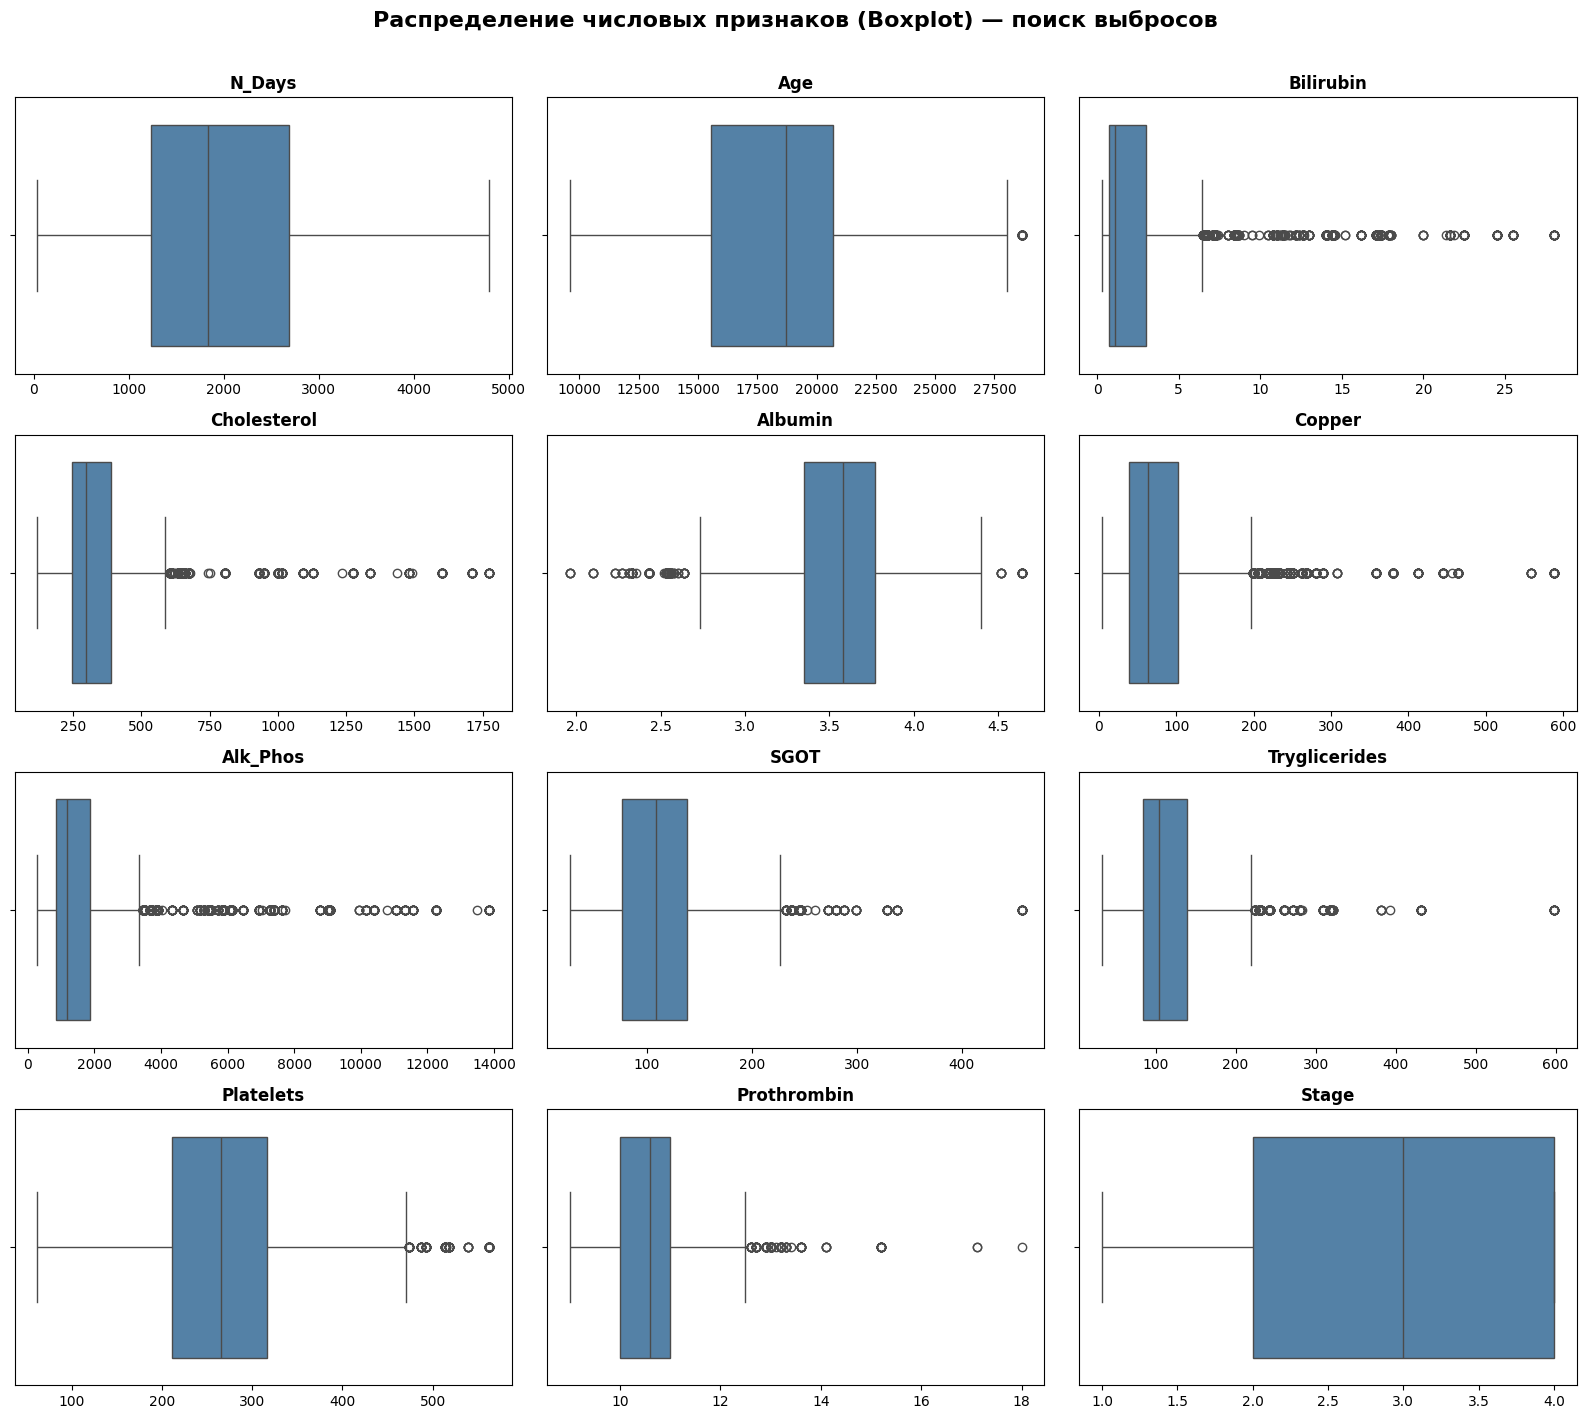

Количество выбросов по правилу 1.5*IQR:

N_Days         :   0 выбросов (0.0%)
Age            :  36 выбросов (0.5%)
Bilirubin      : 789 выбросов (10.0%)
Cholesterol    : 502 выбросов (6.4%)
Albumin        : 178 выбросов (2.3%)
Copper         : 655 выбросов (8.3%)
Alk_Phos       : 792 выбросов (10.0%)
SGOT           : 146 выбросов (1.8%)
Tryglicerides  : 267 выбросов (3.4%)
Platelets      : 114 выбросов (1.4%)
Prothrombin    : 173 выбросов (2.2%)
Stage          :   0 выбросов (0.0%)


In [ ]:
# Основные числовые признаки для анализа выбросов
num_features = ['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin',
                'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets',
                'Prothrombin', 'Stage']

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for idx, col in enumerate(num_features):
    ax = axes[idx]
    sns.boxplot(x=df[col], ax=ax, color='steelblue')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение числовых признаков (Boxplot) — поиск выбросов',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Количественная оценка выбросов по правилу IQR
print("Количество выбросов по правилу 1.5*IQR:\n")
for col in num_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:15s}: {n_out:3d} выбросов ({n_out/len(df)*100:.1f}%)")

### **Проверка аномалий**

In [ ]:
# Гарантируем, что id — обычная колонка
if 'id' not in df.columns:
    df = df.reset_index()

# Определяем колонки, которые реально есть в датафрейме (на случай опечаток)
available_cols = set(df.columns)

def cols_present(cols):
    return [c for c in cols if c in available_cols]

def check_anomaly(mask, title, cols=None):
    subset = df[mask]
    print(f"🔍 {title}: {len(subset)}")
    if len(subset) > 0:
        cols_use = cols_present(cols) if cols else None
        display(subset if cols_use is None else subset[cols_use])
    print("-" * 60)

# 1. Пациентов с Bilirubin = 0
check_anomaly(df['Bilirubin'] == 0, "Пациентов с Bilirubin = 0")

# 2. Пациентов с Albumin = 0
check_anomaly(df['Albumin'] == 0, "Пациентов с Albumin = 0")

# 3. Пациентов с Platelets = 0
check_anomaly(df['Platelets'] == 0, "Пациентов с Platelets = 0")

# 4. Пациентов с Prothrombin = 0
check_anomaly(df['Prothrombin'] == 0, "Пациентов с Prothrombin = 0")

# 5. Пациентов с Cholesterol = 0
check_anomaly(df['Cholesterol'] == 0, "Пациентов с Cholesterol = 0")

# 6. Пациентов младше 18 лет (Age < 6570 дней)
check_anomaly(df['Age'] < 6570, "Пациентов младше 18 лет (Age < 6570 дней)")

# 7. Пациентов с N_Days = 0"
check_anomaly(df['N_Days'] == 0, "Пациентов с N_Days = 0")

# 8. Пациентов со Stage вне {1,2,3,4}
check_anomaly(~df['Stage'].isin([1, 2, 3, 4]), "Пациентов со Stage вне {1,2,3,4}")

# 9. Пациентов с Bilirubin > 20 (тяжёлая желтуха)
check_anomaly(df['Bilirubin'] > 20,
              "Пациентов с Bilirubin > 20 (тяжёлая желтуха)",
              cols=['id', 'Bilirubin', 'Albumin', 'Stage', 'Status'])

# 10. Пациентов с Alk_Phos > 10000
check_anomaly(df['Alk_Phos'] > 10000,
              "Пациентов с Alk_Phos > 10000",
              cols=['id', 'Alk_Phos', 'Bilirubin', 'Stage', 'Status'])

# 11. Пациентов с SGOT > 1000"
check_anomaly(df['SGOT'] > 1000,
              "Пациентов с SGOT > 1000",
              cols=['id', 'SGOT', 'Bilirubin', 'Stage', 'Status'])

# 12. Пациентов с Copper > 500
check_anomaly(df['Copper'] > 500,
              "Пациентов с Copper > 500",
              cols=['id', 'Copper', 'Bilirubin', 'Stage', 'Status'])

# 13. Пациентов с Tryglicerides <= 0
check_anomaly(df['Tryglicerides'] <= 0, "Пациентов с Tryglicerides <= 0")

# 14. Пропуски
print("🔍 Пропуски в данных:")
print(df.isna().sum().sum(), "всего пропущенных значений")

🔍 Пациентов с Bilirubin = 0: 0
------------------------------------------------------------
🔍 Пациентов с Albumin = 0: 0
------------------------------------------------------------
🔍 Пациентов с Platelets = 0: 0
------------------------------------------------------------
🔍 Пациентов с Prothrombin = 0: 0
------------------------------------------------------------
🔍 Пациентов с Cholesterol = 0: 0
------------------------------------------------------------
🔍 Пациентов младше 18 лет (Age < 6570 дней): 0
------------------------------------------------------------
🔍 Пациентов с N_Days = 0: 0
------------------------------------------------------------
🔍 Пациентов со Stage вне {1,2,3,4}: 0
------------------------------------------------------------
🔍 Пациентов с Bilirubin > 20 (тяжёлая желтуха): 79


,id,Bilirubin,Albumin,Stage,Status
29,29,28.0,3.26,3.0,D
213,213,22.5,3.31,2.0,D
284,284,22.5,3.20,4.0,D
288,288,21.6,3.31,3.0,D
308,308,21.6,3.93,4.0,D
...,...,...,...,...,...
7287,7287,21.9,3.51,4.0,D
7572,7572,24.5,3.18,2.0,D
7585,7585,25.5,3.52,4.0,D
7740,7740,22.5,3.34,4.0,D


------------------------------------------------------------
🔍 Пациентов с Alk_Phos > 10000: 114


,id,Alk_Phos,Bilirubin,Stage,Status
105,105,10396.799805,5.5,2.0,C
420,420,10165.000000,1.1,2.0,C
447,447,11046.599609,1.1,3.0,C
465,465,12258.799805,3.3,4.0,C
482,482,11552.000000,3.2,3.0,CL
...,...,...,...,...,...
7407,7407,11046.599609,5.1,4.0,D
7425,7425,13862.400391,1.3,3.0,C
7540,7540,12258.799805,1.8,3.0,D
7729,7729,12258.799805,0.8,3.0,C


------------------------------------------------------------
🔍 Пациентов с SGOT > 1000: 0
------------------------------------------------------------
🔍 Пациентов с Copper > 500: 26


,id,Copper,Bilirubin,Stage,Status
750,750,588.0,6.600000,4.0,D
961,961,588.0,11.400000,4.0,D
1034,1034,588.0,0.800000,3.0,C
1191,1191,558.0,3.500000,4.0,D
1264,1264,558.0,17.400000,2.0,D
1701,1701,588.0,21.600000,4.0,D
1955,1955,558.0,17.100000,4.0,D
2239,2239,588.0,11.400000,4.0,D
2575,2575,588.0,17.200001,4.0,D
3523,3523,588.0,17.400000,4.0,D


------------------------------------------------------------
🔍 Пациентов с Tryglicerides <= 0: 0
------------------------------------------------------------
🔍 Пропуски в данных:
0 всего пропущенных значений


Структураные проверки:
Что ловит: опечатки в категориях ('M ' vs 'M'), лишние пробелы, неожиданные значения, дубликаты пациентов.

In [ ]:
# 1.1 Уникальность id
print("Дубликатов id:", df['id'].duplicated().sum())

# 1.2 Полные дубликаты строк
print("Полных дубликатов строк:", df.duplicated().sum())

# 1.3 Типы данных
print(df.dtypes)

# 1.4 Пропуски
print(df.isna().sum())

# 1.5 Уникальные значения категориальных признаков
for c in ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Status']:
    print(f"{c}: {df[c].unique()}  (n={df[c].nunique()})")

# 1.6 Stage как порядковая
print("Stage:", sorted(df['Stage'].unique()))

Дубликатов id: 0
Полных дубликатов строк: 0
id                 int64
N_Days             int16
Drug              object
Age                int16
Sex               object
Ascites           object
Hepatomegaly      object
Spiders           object
Edema             object
Bilirubin        float32
Cholesterol      float32
Albumin          float32
Copper           float32
Alk_Phos         float32
SGOT             float32
Tryglicerides    float32
Platelets        float32
Prothrombin      float32
Stage            float32
Status            object
dtype: object
id               0
N_Days           0
Drug             0
Age              0
Sex              0
Ascites          0
Hepatomegaly     0
Spiders          0
Edema            0
Bilirubin        0
Cholesterol      0
Albumin          0
Copper           0
Alk_Phos         0
SGOT             0
Tryglicerides    0
Platelets        0
Prothrombin      0
Stage            0
Status           0
dtype: int64
Drug: ['D-penicillamine' 'Placebo']  (n=2)
Sex: [

Медицинские границы: Что ловит: нулевые/отрицательные значения, опечатки на порядок (например Alk_Phos = 13862.4 при норме до ~120), пациентов вне возрастного диапазона исследования.

In [ ]:
# 2.1 Биологически невозможные значения
checks = {
    'Bilirubin':       (df['Bilirubin'] <= 0).sum(),
    'Cholesterol':     (df['Cholesterol'] <= 0).sum(),
    'Albumin':         (df['Albumin'] <= 0).sum(),
    'Copper':          (df['Copper'] <= 0).sum(),
    'Alk_Phos':        (df['Alk_Phos'] <= 0).sum(),
    'SGOT':            (df['SGOT'] <= 0).sum(),
    'Tryglicerides':   (df['Tryglicerides'] <= 0).sum(),
    'Platelets':       (df['Platelets'] <= 0).sum(),
    'Prothrombin':     (df['Prothrombin'] <= 0).sum(),
    'Age':             (df['Age'] <= 0).sum(),
    'N_Days':          (df['N_Days'] < 0).sum(),
}
print(pd.Series(checks, name='кол-во аномалий'))

# 2.2 Клинически допустимые диапазоны
ranges = {
    'Bilirubin':    (0.1, 30),
    'Albumin':      (1.5, 6),
    'Prothrombin':  (8, 20),
    'Platelets':    (50, 600),
    'Age':          (18*365, 100*365),  # дни
}
for col, (lo, hi) in ranges.items():
    out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: вне [{lo}, {hi}] → {out}")

Bilirubin        0
Cholesterol      0
Albumin          0
Copper           0
Alk_Phos         0
SGOT             0
Tryglicerides    0
Platelets        0
Prothrombin      0
Age              0
N_Days           0
Name: кол-во аномалий, dtype: int64
Bilirubin: вне [0.1, 30] → 0
Albumin: вне [1.5, 6] → 0
Prothrombin: вне [8, 20] → 0
Platelets: вне [50, 600] → 0
Age: вне [6570, 36500] → 0


3. Согласованность категориальных и клинических признаков
Что ловит: опечатки в категориях ('y', 'Yes'), несовместимые сочетания (лёгкий Stage с признаками тяжёлой декомпенсации), которые могут быть ошибками ввода.

In [ ]:
# 3.1 Ascites / Hepatomegaly / Spiders / Edema должны быть {N, Y}
for c in ['Ascites', 'Hepatomegaly', 'Spiders']:
    bad = (~df[c].isin(['N','Y'])).sum()
    print(f"{c}: некорректных значений = {bad}")

# Edema имеет {N, S, Y}
print("Edema:", df['Edema'].value_counts().to_dict())

# 3.2 Status — только {C, D, CL}
print("Status:", df['Status'].value_counts().to_dict())

# 3.3 Stage — только {1,2,3,4}
print("Stage:", df['Stage'].value_counts().sort_index().to_dict())

# 3.4 Логическая согласованность: тяжёлый асцит (Edema='Y' или 'S') с низким Albumin
print("Edema=Y/S с Albumin > 3.5:",
      ((df['Edema'].isin(['Y','S'])) & (df['Albumin'] > 3.5)).sum())

# 3.5 Stage 4 vs высокая Bilirubin (в среднем должно быть выше)
print(df.groupby('Stage')['Bilirubin'].agg(['mean','median','count']))

Ascites: некорректных значений = 0
Hepatomegaly: некорректных значений = 0
Spiders: некорректных значений = 0
Edema: {'N': 7161, 'S': 399, 'Y': 345}
Status: {'C': 4965, 'D': 2665, 'CL': 275}
Stage: {1.0: 397, 2.0: 1652, 3.0: 3153, 4.0: 2703}
Edema=Y/S с Albumin > 3.5: 242
           mean  median  count
Stage                         
1.0    1.449874     0.8    397
2.0    1.827845     0.9   1652
3.0    2.172598     0.9   3153
4.0    3.723270     2.0   2703


4. Статистические выбросы (IQR / z-score) Что ловит: формальные выбросы. Важно: в этом датасете большинство — клинически реальные тяжёлые пациенты, а не ошибки.

In [ ]:
num_cols = ['N_Days','Age','Bilirubin','Cholesterol','Albumin','Copper',
            'Alk_Phos','SGOT','Tryglicerides','Platelets','Prothrombin']

# 4.1 IQR-выбросы
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

print(df[num_cols].apply(iqr_outliers).sort_values(ascending=False))

# 4.2 z-score > 3
from scipy import stats
z = np.abs(stats.zscore(df[num_cols], nan_policy='omit'))
print((z > 3).sum(axis=0))

# 4.3 Модифицированный z-score (MAD) — устойчивее
def mad_outliers(s):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0: return 0
    return ((0.6745 * (s - med) / mad).abs() > 3.5).sum()

print(df[num_cols].apply(mad_outliers))

Alk_Phos         792
Bilirubin        789
Copper           655
Cholesterol      502
Tryglicerides    267
Albumin          178
Prothrombin      173
SGOT             146
Platelets        114
Age               36
N_Days             0
dtype: int64
[  0   0 281 216 106 151 189  80 113  41 113]
N_Days              0
Age                 0
Bilirubin        1312
Cholesterol       426
Albumin            86
Copper            655
Alk_Phos          744
SGOT               80
Tryglicerides     143
Platelets          36
Prothrombin        67
dtype: int64


5. Проверка распределений Что ловит: сильную скошенность (Bilirubin, Copper, Alk_Phos) → сигнал к log1p-преобразованию перед моделированием.

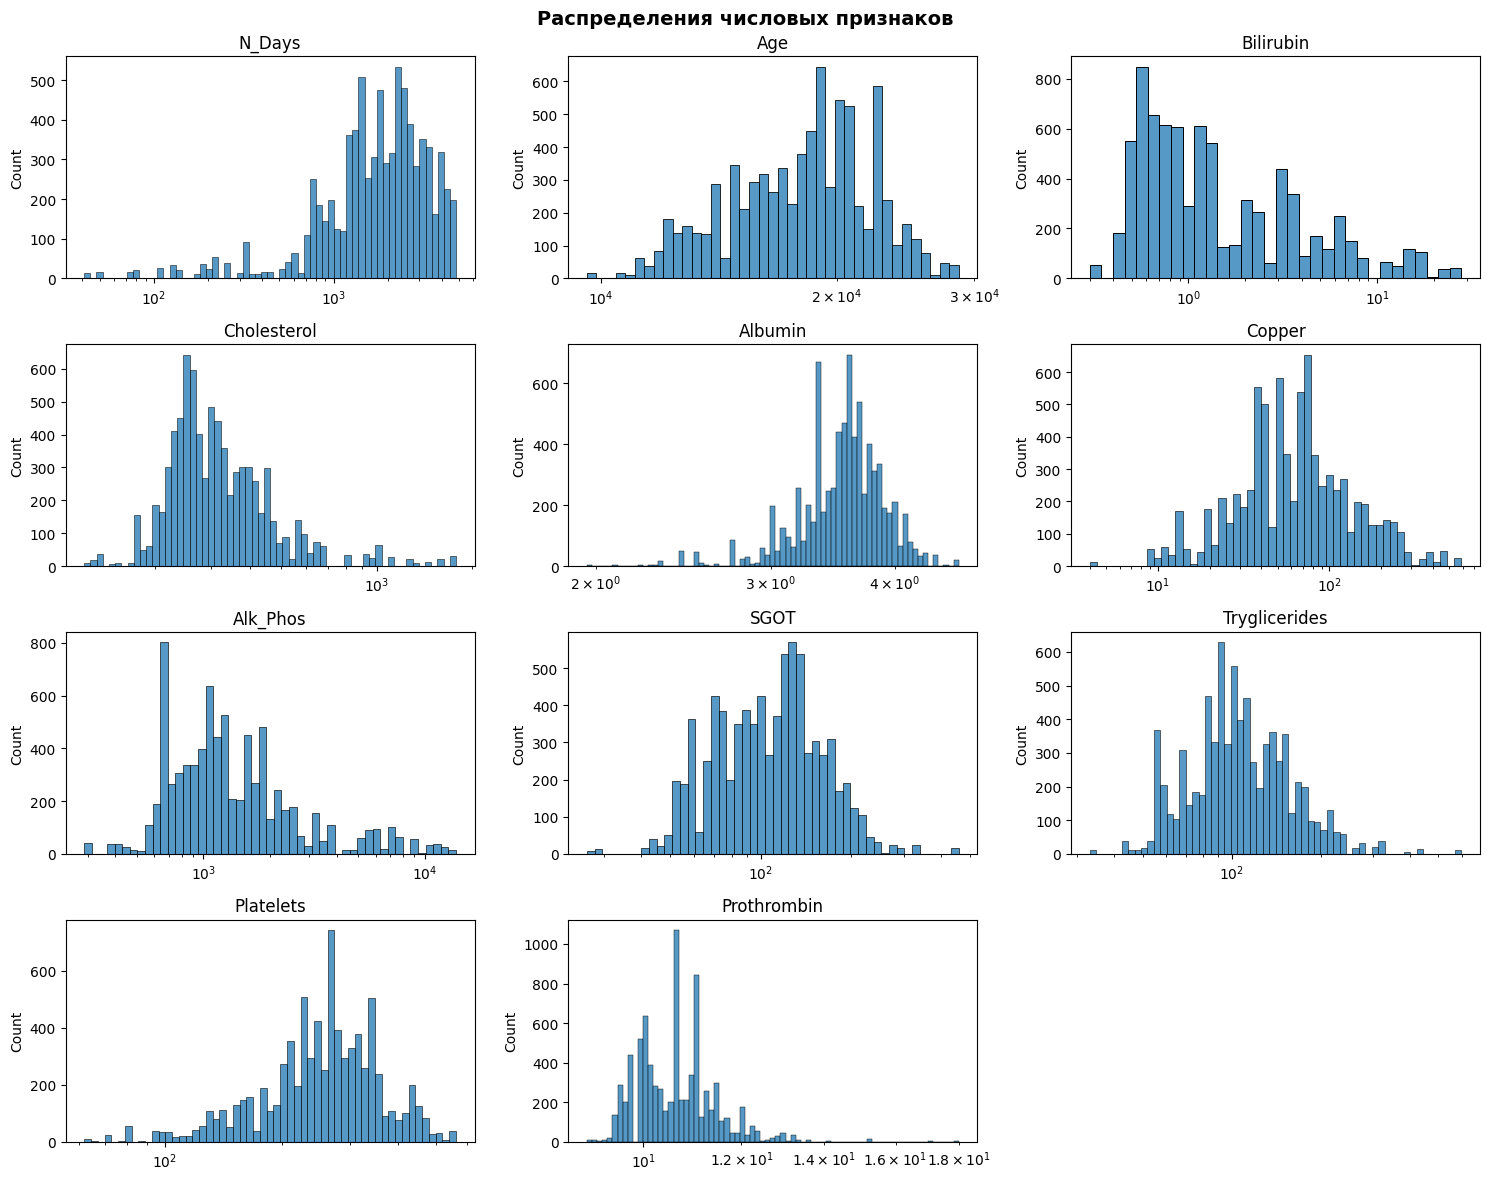

In [ ]:
import matplotlib.pyplot as plt, seaborn as sns

fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for ax, c in zip(axes.flatten(), num_cols):
    use_log = bool(df[c].min() > 0)          # приводим к чистому bool
    sns.histplot(
        df[c],
        kde=not use_log,                      # KDE плохо работает на лог-шкале
        ax=ax,
        log_scale=use_log if use_log else False
    )
    ax.set_title(c)
    ax.set_xlabel('')

# Если признаков меньше, чем ячеек — скрываем пустые
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)

plt.suptitle('Распределения числовых признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

6. Проверка на «странные» комбинации (multivariate) Что ловит: подозрительные сочетания, которые могут быть ошибками ввода (например, перепутаны единицы измерения у конкретного пациента).

In [ ]:
# 6.1 Очень высокий Alk_Phos + нормальный Bilirubin (необычно при циррозе)
mask = (df['Alk_Phos'] > 5000) & (df['Bilirubin'] < 1.5)
print("Alk_Phos > 5000 и Bilirubin < 1.5:", mask.sum())
display(df.loc[mask, ['id','Alk_Phos','Bilirubin','Stage','Status']])

# 6.2 Очень высокий SGOT но нормальный Bilirubin
mask = (df['SGOT'] > 200) & (df['Bilirubin'] < 1.0)
print("SGOT > 200 и Bilirubin < 1:", mask.sum())

# 6.3 Минимальный Prothrombin (плохой прогноз) при Status='C' (цензурирован)
mask = (df['Prothrombin'] >= 14) & (df['Status'] == 'C')
print("Prothrombin >= 14 при Status=C:", mask.sum())

Alk_Phos > 5000 и Bilirubin < 1.5: 357


,id,Alk_Phos,Bilirubin,Stage,Status
5,5,6456.200195,0.6,3.0,D
53,53,5430.200195,1.1,3.0,C
120,120,7277.000000,0.6,3.0,C
125,125,5833.000000,0.8,3.0,D
137,137,9066.799805,0.7,4.0,D
...,...,...,...,...,...
7784,7784,12258.799805,1.3,1.0,C
7837,7837,6121.799805,0.7,4.0,D
7841,7841,7277.000000,0.7,4.0,C
7850,7850,5430.200195,0.8,3.0,C


SGOT > 200 и Bilirubin < 1: 61
Prothrombin >= 14 при Status=C: 5


7. Проверка целевой переменной / времени Что ловит: дисбаланс классов, подозрительно длинные/короткие наблюдения, несоответствие Stage ↔ Status.

In [ ]:
# 7.1 Баланс классов Status
print(df['Status'].value_counts(normalize=True))

# 7.2 N_Days — выживаемость
print(df['N_Days'].describe())
print("Доля N_Days < 100:", (df['N_Days'] < 100).mean())

# 7.3 Status vs N_Days (D должен в среднем иметь меньше дней)
print(df.groupby('Status')['N_Days'].agg(['mean','median','count']))

# 7.4 Stage vs Status (Stage 4 → больше D)
print(pd.crosstab(df['Stage'], df['Status'], normalize='index'))

Status
C     0.628083
D     0.337128
CL    0.034788
Name: proportion, dtype: float64
count    7905.000000
mean     2030.173308
std      1094.233744
min        41.000000
25%      1230.000000
50%      1831.000000
75%      2689.000000
max      4795.000000
Name: N_Days, dtype: float64
Доля N_Days < 100: 0.008349146110056925
               mean  median  count
Status                            
C       2322.529305  2216.0   4965
CL      1610.105455  1435.0    275
D       1528.849156  1216.0   2665
Status         C        CL         D
Stage                               
1.0     0.884131  0.017632  0.098237
2.0     0.782688  0.028450  0.188862
3.0     0.728830  0.035839  0.235331
4.0     0.378468  0.039956  0.581576


8. Проверка Drug vs Placebo (дизайн исследования) Что ловит: нарушение рандомизации, дисбаланс групп — важно для интерпретации причинного эффекта.

In [ ]:
# 8.1 Сбалансированность групп
print(df['Drug'].value_counts())
print(pd.crosstab(df['Drug'], df['Status']))

# 8.2 Сравнение базовых характеристик (должны быть похожи при рандомизации)
df.groupby('Drug')[['Age','Bilirubin','Albumin','Platelets']].mean()

Drug
Placebo            4010
D-penicillamine    3895
Name: count, dtype: int64
Status              C   CL     D
Drug                            
D-penicillamine  2405  151  1339
Placebo          2560  124  1326


,Age,Bilirubin,Albumin,Platelets
Drug,,,,
D-penicillamine,18716.898331,2.450218,3.537759,263.527344
Placebo,18039.252868,2.734613,3.558583,266.881805


9. Мультиколлинеарность (перед моделированием) Что ловит: сильные корреляции (например, SGOT ↔ Alk_Phos), которые мешают линейным моделям.

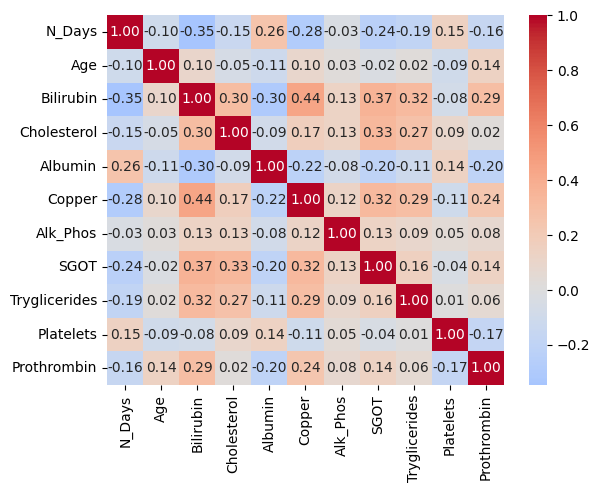

Bilirubin    Copper           0.442223
             SGOT             0.368653
N_Days       Bilirubin       -0.346434
Cholesterol  SGOT             0.326864
Copper       SGOT             0.323226
Bilirubin    Tryglicerides    0.315681
             Albumin         -0.303191
             Cholesterol      0.302153
             Prothrombin      0.294325
Copper       Tryglicerides    0.290435
dtype: float64


In [ ]:
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

# Пары с |r| > 0.6
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
print(corr.where(mask).stack().sort_values(key=abs, ascending=False).head(10))

10. Проверка константных / почти константных признаков Что ловит: колонки, которые не несут информации (стоит удалить перед моделью).

In [ ]:
nunique = df.nunique()
print(nunique[nunique <= 2])   # константные или почти

Drug            2
Sex             2
Ascites         2
Hepatomegaly    2
Spiders         2
dtype: int64


# **Часть 4. Одномерный анализ**

In [ ]:
num_cols = ['N_Days','Age','Bilirubin','Cholesterol','Albumin','Copper',
            'Alk_Phos','SGOT','Tryglicerides','Platelets','Prothrombin']
cat_cols = ['Drug','Sex','Ascites','Hepatomegaly','Spiders','Edema','Stage','Status']

Вариант 1. Описательные статистики (числовые) Самый базовый слой: центр, разброс, форма распределения. Что смотреть: skew и kurt покажут, какие признаки нужно логарифмировать перед моделью (Bilirubin, Copper, Alk_Phos, SGOT — сильно скошены вправо). cv покажет, где разброс относительно среднего особенно велик.

In [ ]:
desc = df[num_cols].agg([
    'count','mean','std','min',
    lambda s: s.quantile(.25),
    'median',
    lambda s: s.quantile(.75),
    'max','skew','kurt'
]).T
desc.columns = ['count','mean','std','min','q25','median','q75','max','skew','kurt']
desc['cv'] = desc['std'] / desc['mean']          # коэффициент вариации
desc['iqr'] = desc['q75'] - desc['q25']
display(desc.round(2))

,count,mean,std,min,q25,median,q75,max,skew,kurt,cv,iqr
N_Days,7905.0,2030.17,1094.23,41.00,1230.00,1831.00,2689.00,4795.00,0.45,-0.49,0.54,1459.00
Age,7905.0,18373.15,3679.96,9598.00,15574.00,18713.00,20684.00,28650.00,0.08,-0.50,0.20,5110.00
Bilirubin,7905.0,2.59,3.81,0.30,0.70,1.10,3.00,28.00,3.34,12.91,1.47,2.30
Cholesterol,7905.0,350.56,195.38,120.00,248.00,298.00,390.00,1775.00,3.68,18.16,0.56,142.00
Albumin,7905.0,3.55,0.35,1.96,3.35,3.58,3.77,4.64,-0.56,1.34,0.10,0.42
Copper,7905.0,83.90,75.90,4.00,39.00,63.00,102.00,588.00,2.70,10.21,0.90,63.00
Alk_Phos,7905.0,1816.75,1903.75,289.00,834.00,1181.00,1857.00,13862.40,3.20,11.60,1.05,1023.00
SGOT,7905.0,114.60,48.79,26.35,75.95,108.50,137.95,457.25,1.53,5.82,0.43,62.00
Tryglicerides,7905.0,115.34,52.53,33.00,84.00,104.00,139.00,598.00,2.63,15.05,0.46,55.00
Platelets,7905.0,265.23,87.47,62.00,211.00,265.00,316.00,563.00,0.42,0.33,0.33,105.00


Вариант 2. Гистограммы + KDE (форма распределения) Что смотреть: бимодальность, тяжёлые хвосты, «шипы» на границах — последние часто означают округление или граничные значения.

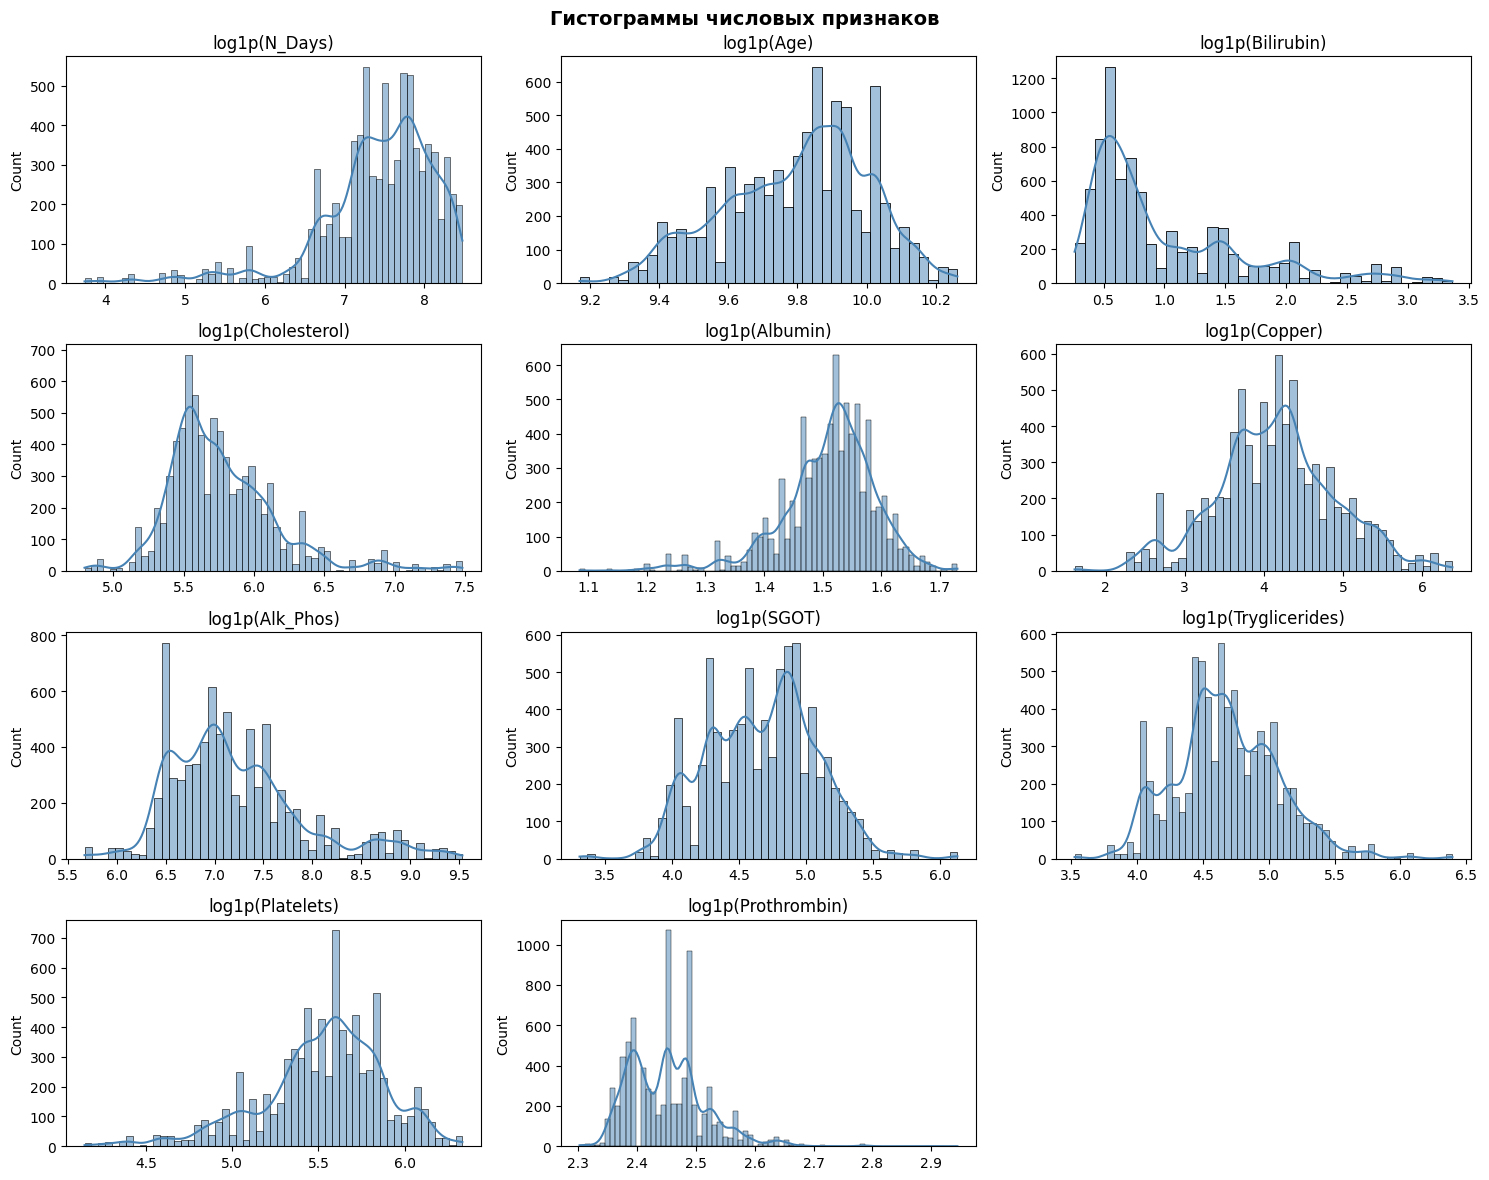

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    data = df[c].dropna()
    use_log = bool((data > 0).all())
    if use_log:
        sns.histplot(np.log1p(data), kde=True, ax=ax, color='steelblue')
        ax.set_title(f'log1p({c})')
    else:
        sns.histplot(data, kde=True, ax=ax, color='steelblue')
        ax.set_title(c)
    ax.set_xlabel('')
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Гистограммы числовых признаков', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

Вариант 3. Boxplot + violinplot (выбросы и плотность) Что смотреть: «точки» за усами — формальные выбросы; «толстые» участки violin — модальные значения.

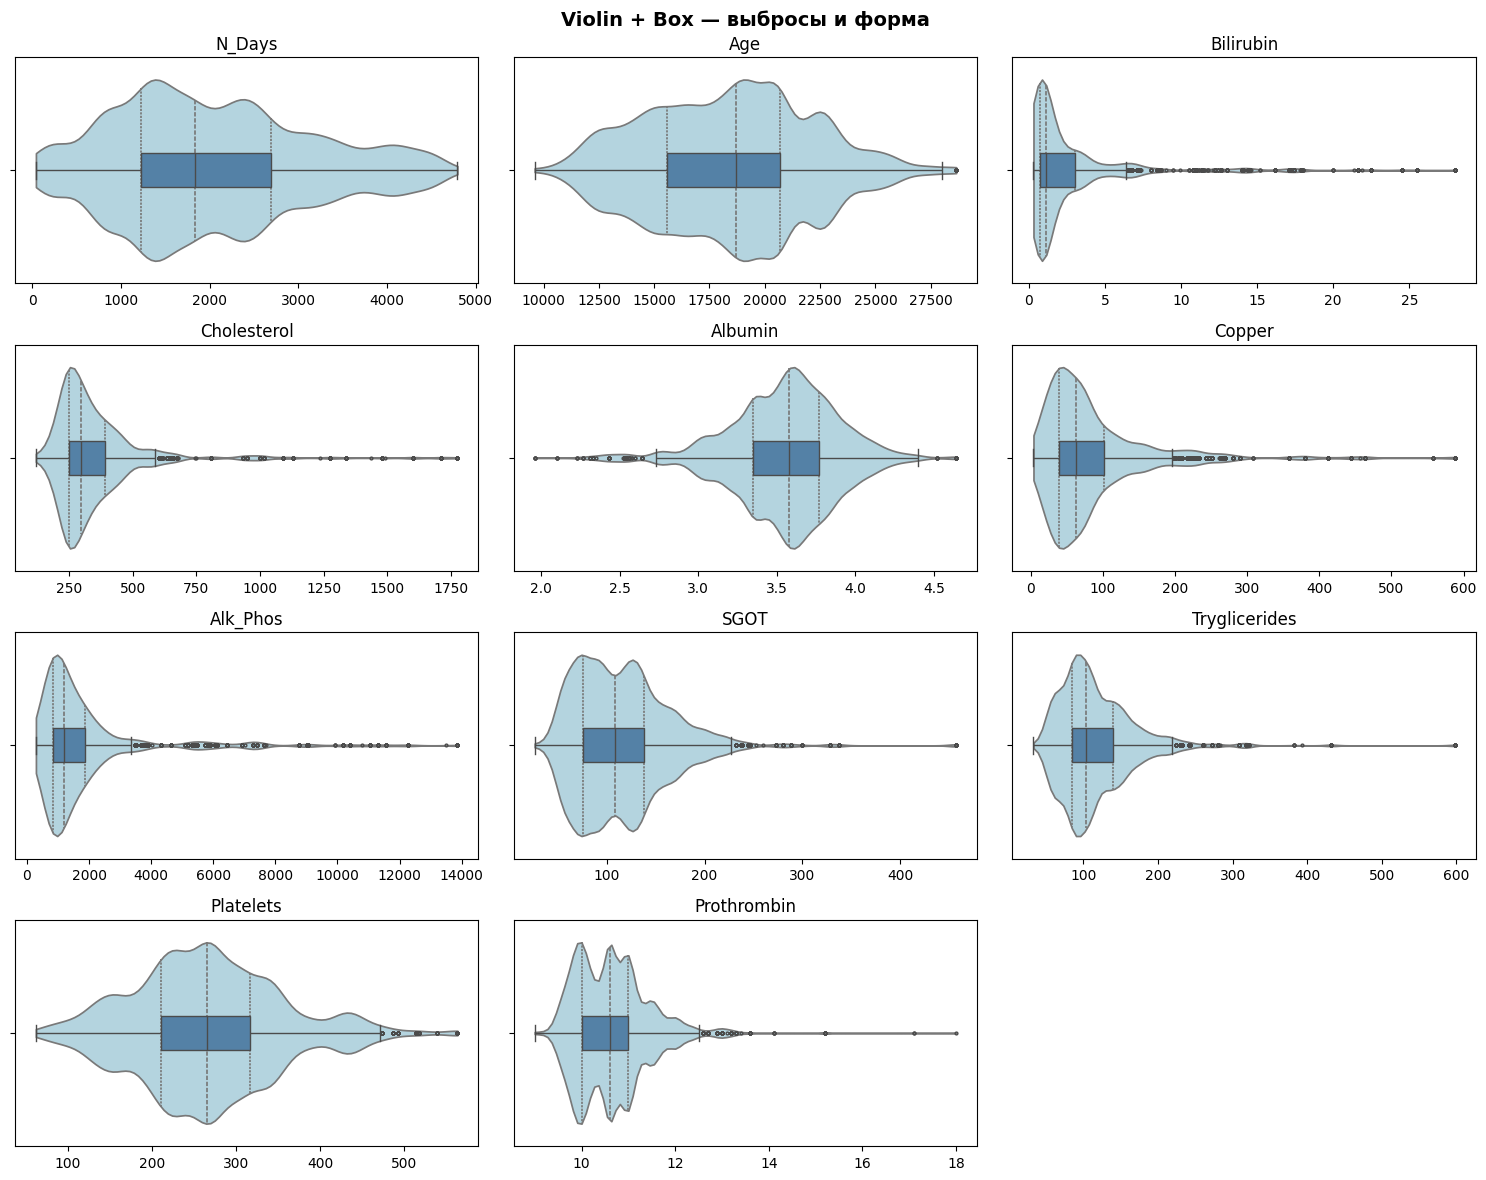

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    sns.violinplot(x=df[c], ax=ax, inner='quartile', color='lightblue', cut=0)
    sns.boxplot(x=df[c], ax=ax, width=0.15, color='steelblue', fliersize=2)
    ax.set_title(c); ax.set_xlabel('')
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Violin + Box — выбросы и форма', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

 Вариант 4. QQ-plot (нормальность) Что смотреть: отклонение от прямой на хвостах = ненормальность. Особенно полезно перед t-тестом или линейной регрессией.

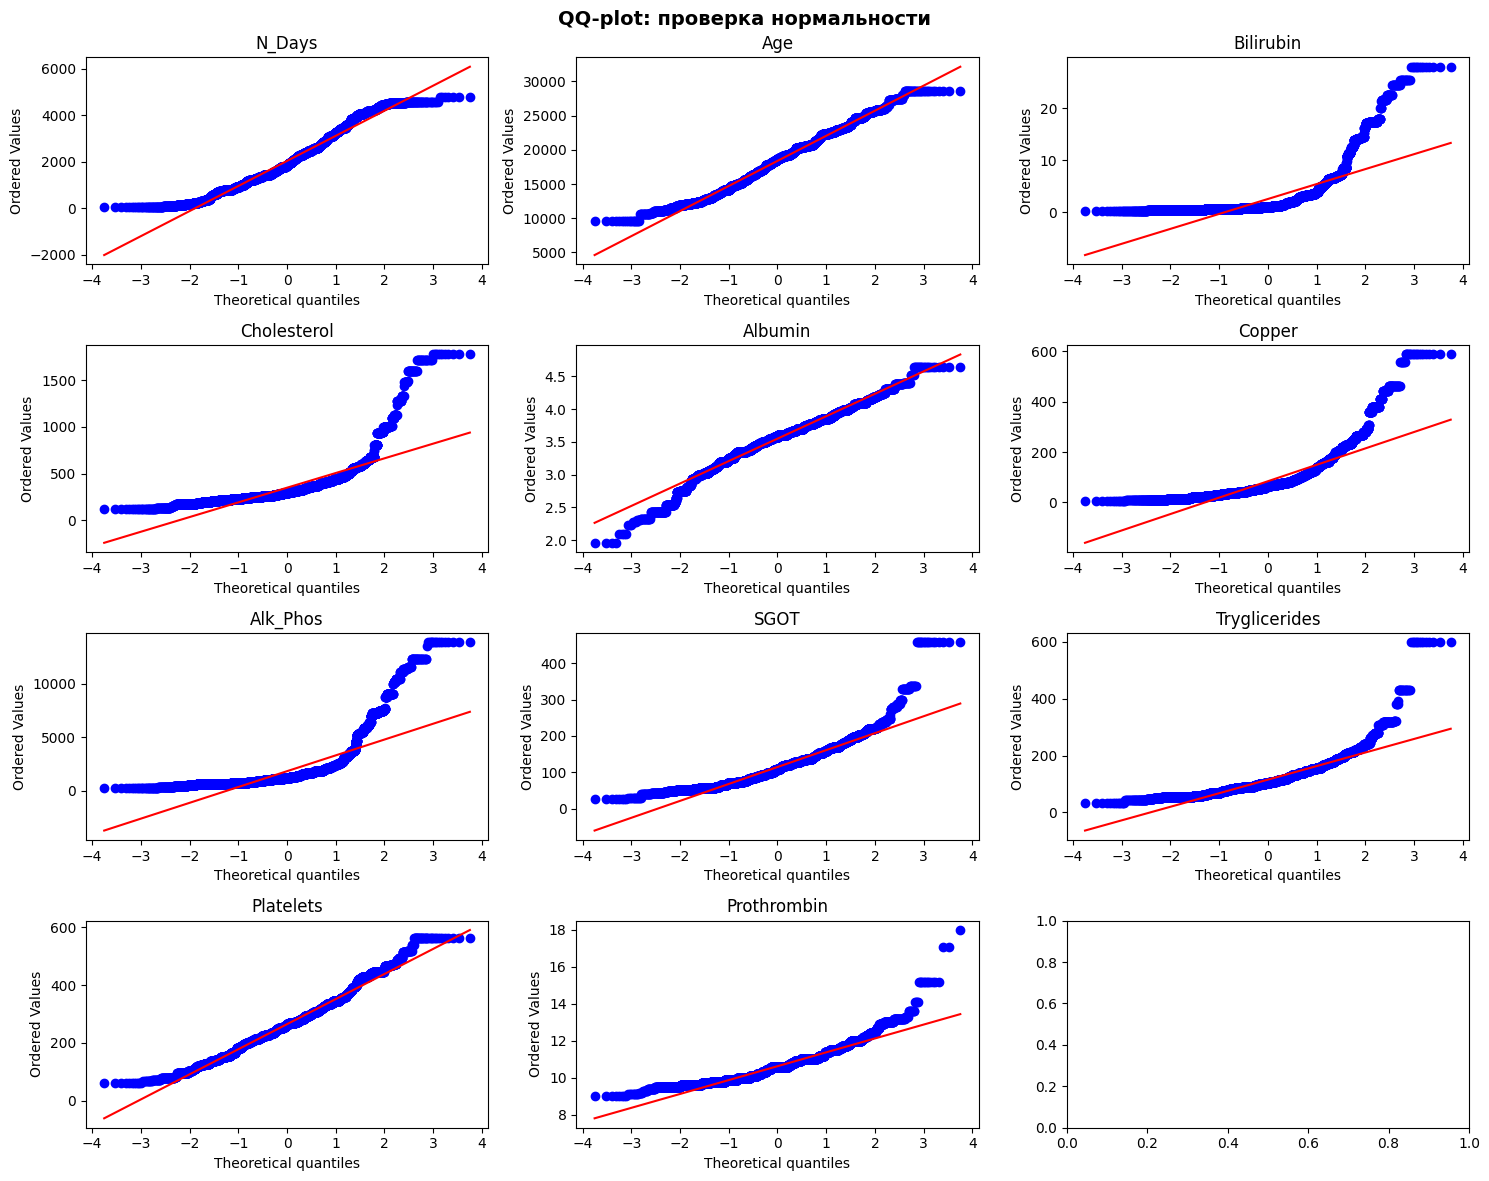

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, c in zip(axes.flatten(), num_cols):
    stats.probplot(df[c].dropna(), dist='norm', plot=ax)
    ax.set_title(c)
plt.suptitle('QQ-plot: проверка нормальности', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

Вариант 5. Тесты нормальности (формальная проверка) Что смотреть: если p < 0.05 — гипотеза нормальности отвергается. В этом датасете все признаки, скорее всего, ненормальны → нужны лог-преобразования или непараметрические тесты.

In [ ]:
results = []
for c in num_cols:
    s = df[c].dropna()
    s_sample = s.sample(min(5000, len(s)), random_state=42)  # ограничение для Shapiro
    results.append({
        'feature': c,
        'Shapiro_p':  stats.shapiro(s_sample).pvalue,
        'DAgostino_p': stats.normaltest(s).pvalue,
        'skew': s.skew(),
        'kurt': s.kurt(),
        'is_normal_5%': stats.normaltest(s).pvalue > 0.05
    })
pd.DataFrame(results).round(4)

,feature,Shapiro_p,DAgostino_p,skew,kurt,is_normal_5%
0,N_Days,0.0,0.0,0.4487,-0.4940,False
1,Age,0.0,0.0,0.0841,-0.4974,False
2,Bilirubin,0.0,0.0,3.3397,12.9088,False
3,Cholesterol,0.0,0.0,3.6797,18.1623,False
4,Albumin,0.0,0.0,-0.5611,1.3396,False
5,Copper,0.0,0.0,2.7017,10.2130,False
6,Alk_Phos,0.0,0.0,3.1956,11.5998,False
7,SGOT,0.0,0.0,1.5348,5.8168,False
8,Tryglicerides,0.0,0.0,2.6339,15.0481,False
9,Platelets,0.0,0.0,0.4200,0.3306,False


Вариант 6. Категориальные признаки — частоты Что смотреть:

Дисбаланс (Status = C/D/CL, Edema = N/S/Y) — важно для стратификации.

Редкие категории — если у категории < 5% наблюдений, её может стоить объединить.

Доминирующий класс — если > 90%, признак почти константа.

In [ ]:
for c in cat_cols:
    vc = df[c].value_counts().sort_index()
    pct = (vc / len(df) * 100).round(1)
    print(f"\n=== {c} ===")
    print(pd.DataFrame({'count': vc, 'pct %': pct}))


=== Drug ===
                 count  pct %
Drug                         
D-penicillamine   3895   49.3
Placebo           4010   50.7

=== Sex ===
     count  pct %
Sex              
F     7336   92.8
M      569    7.2

=== Ascites ===
         count  pct %
Ascites              
N         7525   95.2
Y          380    4.8

=== Hepatomegaly ===
              count  pct %
Hepatomegaly              
N              3863   48.9
Y              4042   51.1

=== Spiders ===
         count  pct %
Spiders              
N         5966   75.5
Y         1939   24.5

=== Edema ===
       count  pct %
Edema              
N       7161   90.6
S        399    5.0
Y        345    4.4

=== Stage ===
       count  pct %
Stage              
1.0      397    5.0
2.0     1652   20.9
3.0     3153   39.9
4.0     2703   34.2

=== Status ===
        count  pct %
Status              
C        4965   62.8
CL        275    3.5
D        2665   33.7


Вариант 7. Визуализация категориальных — bar / pie Что смотреть: визуальный дисбаланс, редкие бары (< 5%), «плоские» признаки (бинарные с сильным перекосом, например Ascites ≈ 90% N).

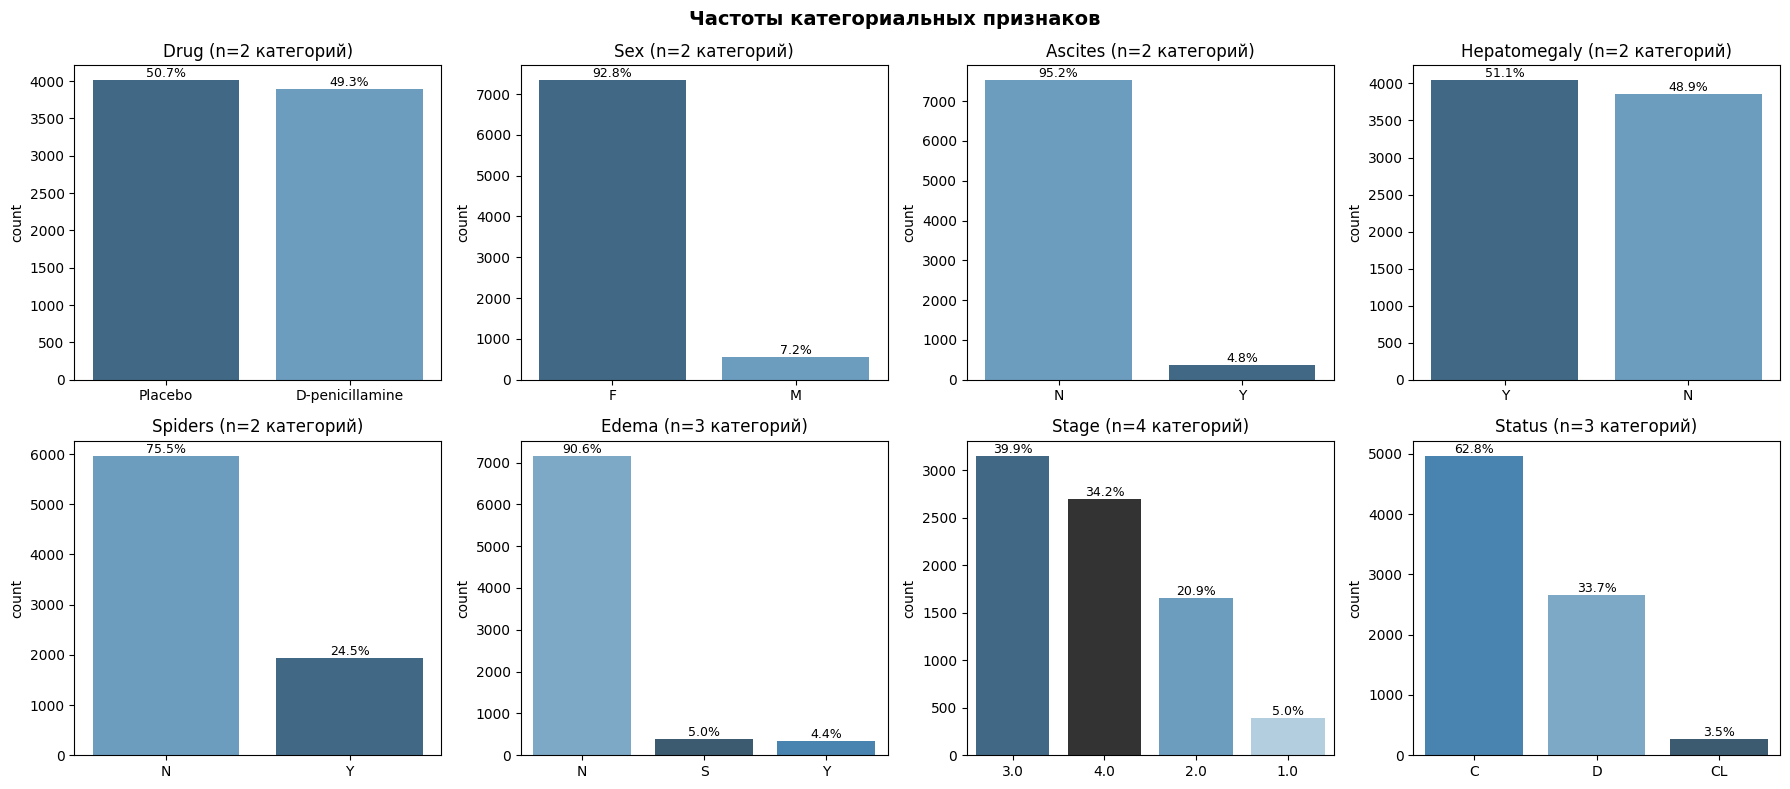

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flatten(), cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax,
                  palette='Blues_d', hue=c, legend=False)
    ax.set_title(f'{c} (n={df[c].nunique()} категорий)')
    ax.set_xlabel('')
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(f'{h/len(df)*100:.1f}%',
                    (p.get_x()+p.get_width()/2, h),
                    ha='center', va='bottom', fontsize=9)
plt.suptitle('Частоты категориальных признаков', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

Вариант 8. Целевые признаки — Status и N_Days (survival-контекст) Что смотреть: доля D (смерть) vs C (цензурировано) — это главный дисбаланс для задачи выживаемости. N_Days имеет длинный правый хвост (максимум ~4500 дней) — это нормально для survival-данных.

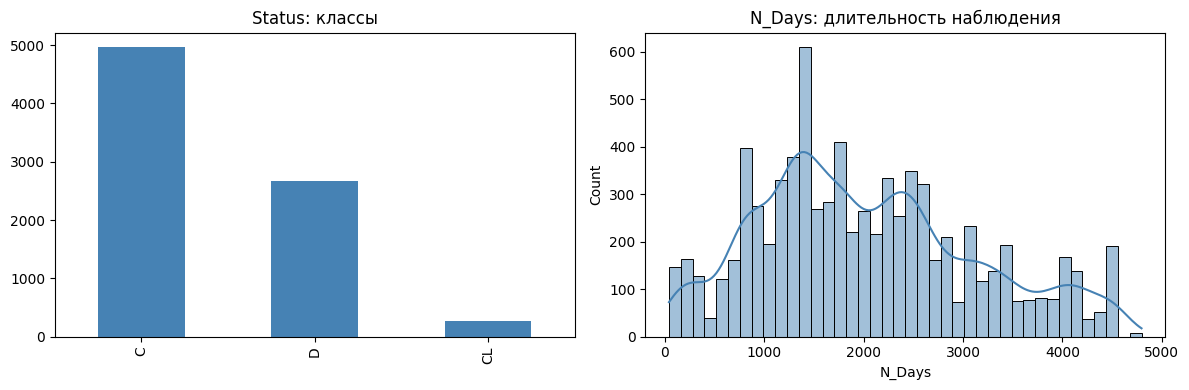

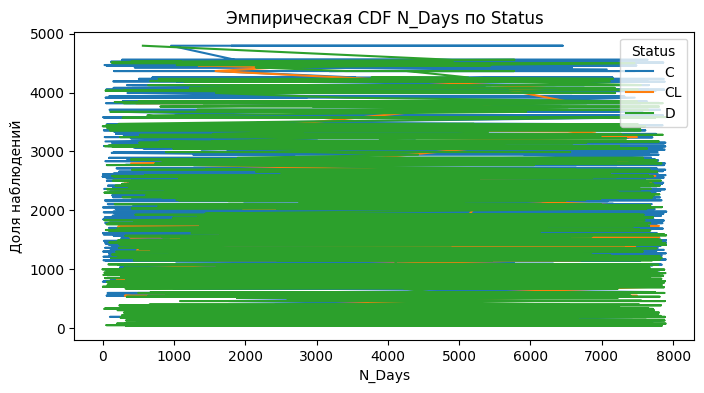

In [ ]:
# 8.1 Status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['Status'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Status: классы'); axes[0].set_xlabel('')

# 8.2 N_Days
sns.histplot(df['N_Days'], bins=40, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('N_Days: длительность наблюдения')
plt.tight_layout(); plt.show()

# 8.3 CDF выживаемости по Status (рудиментарно)
fig, ax = plt.subplots(figsize=(8, 4))
for s, g in df.groupby('Status'):
    g['N_Days'].sort_values().plot(
        kind='line', ax=ax, label=s,
        y=np.linspace(0, 1, len(g)),  # накопленная доля
    )
ax.set_xlabel('N_Days'); ax.set_ylabel('Доля наблюдений')
ax.set_title('Эмпирическая CDF N_Days по Status')
ax.legend(title='Status'); plt.show()

Вариант 9. Сводный «одномерный отчёт» — одна таблица Что смотреть: одна таблица — быстрый обзор всех признаков разом. Отлично подходит для отчёта перед моделированием.

In [ ]:
def univariate_report(df, num_cols, cat_cols):
    rows = []
    for c in num_cols:
        s = df[c].dropna()
        rows.append({
            'type':'numeric','feature':c,'n':len(s),
            'min':s.min(),'q25':s.quantile(.25),'median':s.median(),
            'q75':s.quantile(.75),'max':s.max(),
            'mean':s.mean(),'std':s.std(),
            'skew':s.skew(),'kurt':s.kurt(),
            'n_outliers_iqr': int(((s < s.quantile(.25)-1.5*(s.quantile(.75)-s.quantile(.25))) |
                                   (s > s.quantile(.75)+1.5*(s.quantile(.75)-s.quantile(.25)))).sum())
        })
    for c in cat_cols:
        vc = df[c].value_counts()
        rows.append({
            'type':'categorical','feature':c,'n':df[c].notna().sum(),
            'n_categories': df[c].nunique(),
            'top': vc.index[0],'top_pct': round(vc.iloc[0]/len(df)*100,1),
            'rarest_pct': round(vc.iloc[-1]/len(df)*100,1)
        })
    return pd.DataFrame(rows)

report = univariate_report(df, num_cols, cat_cols)
display(report)

,type,feature,n,min,q25,median,q75,max,mean,std,skew,kurt,n_outliers_iqr,n_categories,top,top_pct,rarest_pct
0,numeric,N_Days,7905,41.00,1230.000000,1831.00,2689.000000,4795.000000,2030.173308,1094.233744,0.448660,-0.494017,0.0,NaN,NaN,NaN,NaN
1,numeric,Age,7905,9598.00,15574.000000,18713.00,20684.000000,28650.000000,18373.146490,3679.958739,0.084091,-0.497382,36.0,NaN,NaN,NaN,NaN
2,numeric,Bilirubin,7905,0.30,0.700000,1.10,3.000000,28.000000,2.594485,3.812942,3.339695,12.908825,789.0,NaN,NaN,NaN,NaN
3,numeric,Cholesterol,7905,120.00,248.000000,298.00,390.000000,1775.000000,350.561920,195.379532,3.679657,18.162327,502.0,NaN,NaN,NaN,NaN
4,numeric,Albumin,7905,1.96,3.350000,3.58,3.770000,4.640000,3.548322,0.346169,-0.561149,1.339621,178.0,NaN,NaN,NaN,NaN
5,numeric,Copper,7905,4.00,39.000000,63.00,102.000000,588.000000,83.902847,75.899193,2.701736,10.212990,655.0,NaN,NaN,NaN,NaN
6,numeric,Alk_Phos,7905,289.00,834.000000,1181.00,1857.000000,13862.400391,1816.745239,1903.753418,3.195558,11.599751,792.0,NaN,NaN,NaN,NaN
7,numeric,SGOT,7905,26.35,75.949997,108.50,137.949997,457.250000,114.604599,48.790924,1.534806,5.816788,146.0,NaN,NaN,NaN,NaN
8,numeric,Tryglicerides,7905,33.00,84.000000,104.00,139.000000,598.000000,115.340164,52.530540,2.633921,15.048119,267.0,NaN,NaN,NaN,NaN
9,numeric,Platelets,7905,62.00,211.000000,265.00,316.000000,563.000000,265.228973,87.465652,0.420048,0.330578,114.0,NaN,NaN,NaN,NaN


# **Часть 5. Многомерный анализ**

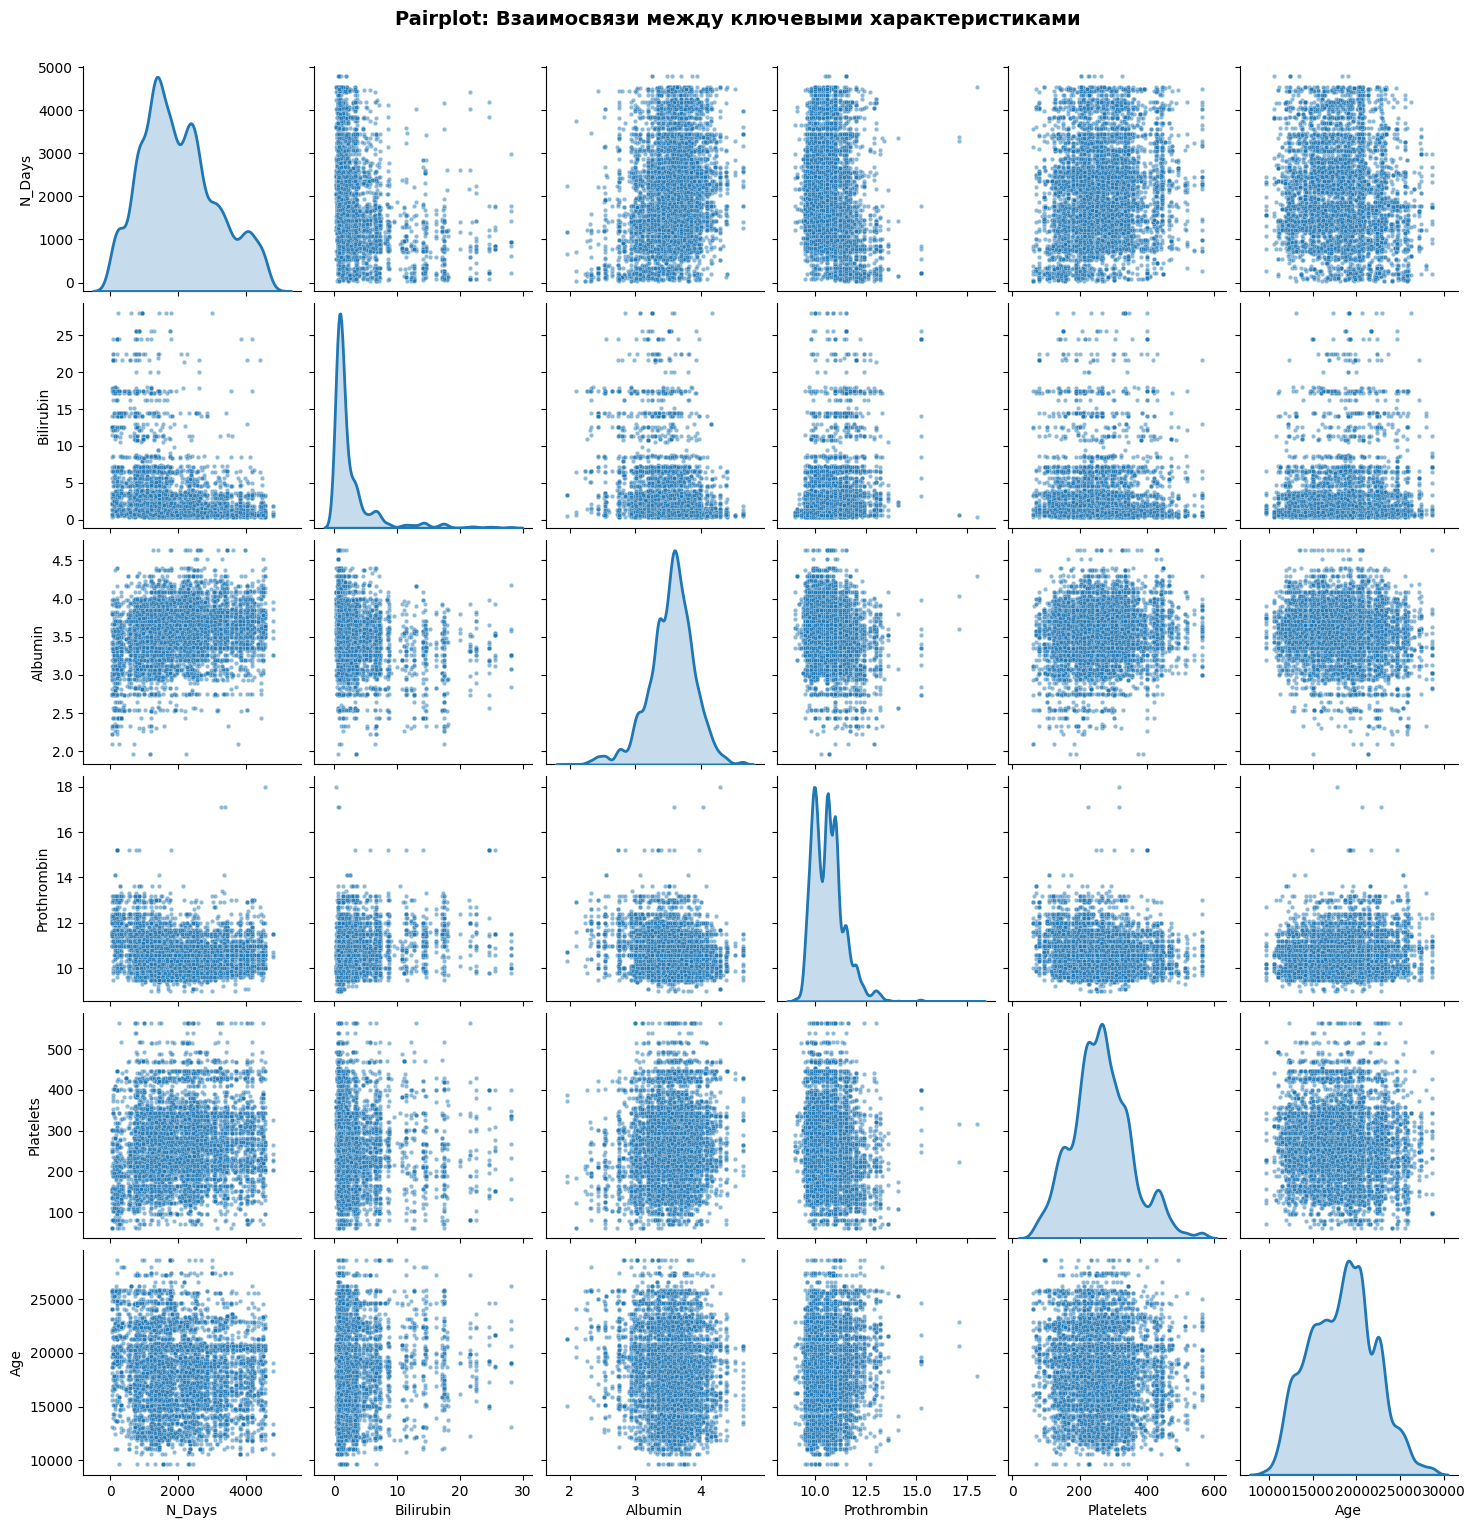

In [ ]:
df_unique = df.drop_duplicates(subset='id')   # на случай дубликатов id

pair_cols = ['N_Days', 'Bilirubin', 'Albumin', 'Prothrombin',
             'Platelets', 'Age']

sns.pairplot(df_unique[pair_cols],
             diag_kind='kde',
             plot_kws={'alpha': 0.5, 's': 10},
             diag_kws={'linewidth': 2})
plt.suptitle('Pairplot: Взаимосвязи между ключевыми характеристиками',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

**5.2 Корреляционный анализ с φk (phik)**

In [ ]:
# Импорт библиотеки phik
!pip install phik
import phik
from phik import resources, report

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 8.5 MB/s  0:00:00


### **Матрица корреляций φk**

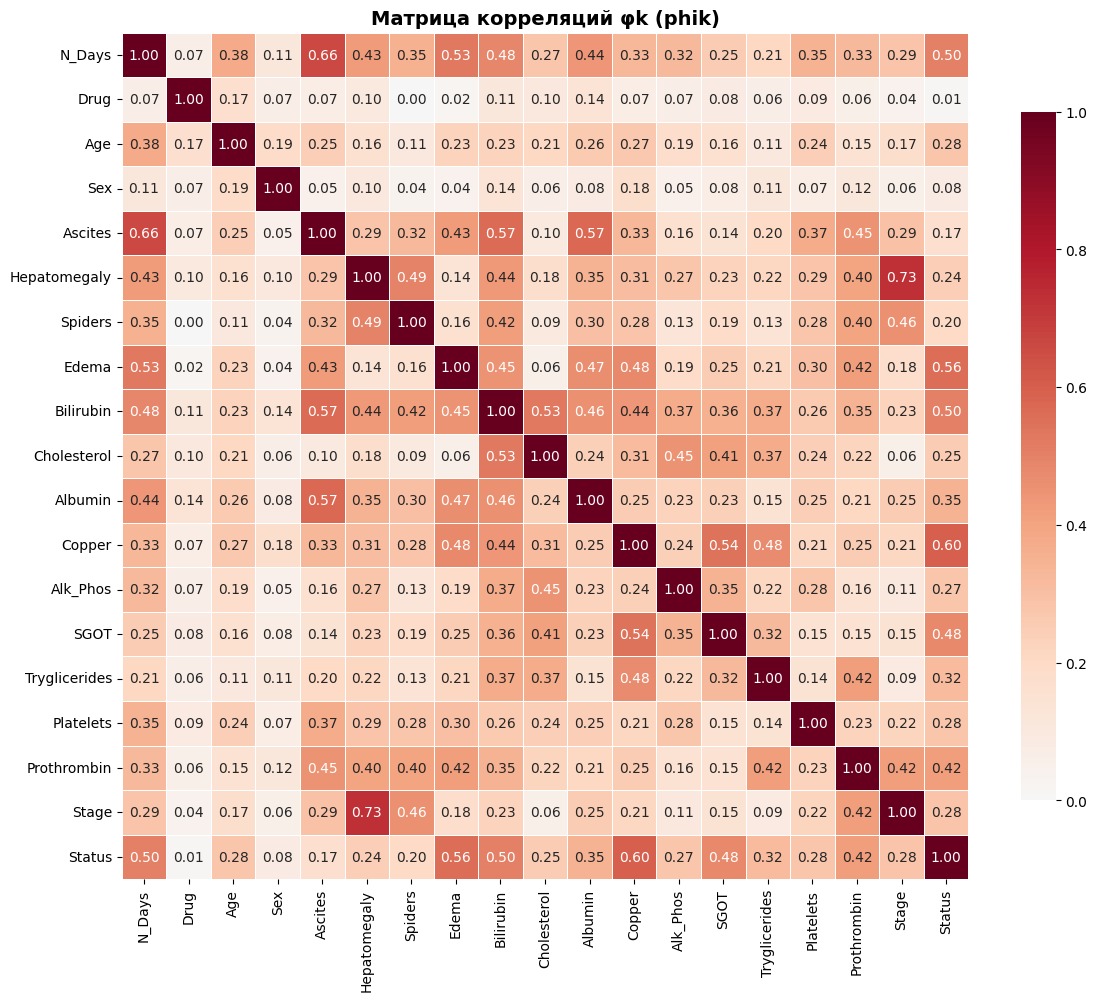

In [ ]:
df_unique = df.drop_duplicates(subset='id')   # защита от дубликатов

# Интервальные (непрерывные) признаки
interval_cols = ['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin',
                 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides',
                 'Platelets', 'Prothrombin']

# Считаем phik-матрицу по всем признакам (числовым + категориальным)
phik_matrix = df_unique.drop(columns=['id']).phik_matrix(interval_cols=interval_cols)

# Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций φk (phik)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# **Часть 6. Сегментированный анализ**


Что смотреть: Stage 1 должен давать наибольшую медиану N_Days, Stage 4 — наименьшую. Если порядок нарушен — либо шум из-за малых подгрупп, либо данные требуют пересмотра.

In [ ]:
# Топ-5 стадий по медианной выживаемости (N_Days)
top_stages_by_days = (
    df[df['N_Days'] != 0]                    # аналог popularity != 0
      .groupby('Stage', observed=True)['N_Days']
      .median()
      .sort_values(ascending=False)
      .head(5)
)

print("🔝 Топ-5 стадий по медианной выживаемости (N_Days):")
print(top_stages_by_days.round(1))

🔝 Топ-5 стадий по медианной выживаемости (N_Days):
Stage
1.0    2255.0
2.0    2221.0
3.0    1951.0
4.0    1455.0
Name: N_Days, dtype: float64


In [ ]:
# «Ключевые» числовые признаки для сравнения
features_for_comparison = ['Bilirubin', 'Albumin', 'Prothrombin',
                           'Platelets', 'Copper', 'SGOT']

# Топ-группы, выбранные ранее (аналог top_genres_by_popularity)
selected_stages = top_stages_by_days.index.tolist()   # из предыдущего шага

# Медианы по группам
stage_stats = (df[df['Stage'].isin(selected_stages)]
               .groupby('Stage', observed=True)[features_for_comparison]
               .median())

print("📊 Медианы ключевых признаков по топ-стадиям:")
display(stage_stats.round(2))

📊 Медианы ключевых признаков по топ-стадиям:


,Bilirubin,Albumin,Prothrombin,Platelets,Copper,SGOT
Stage,,,,,,
1.0,0.8,3.64,10.5,271.0,52.0,93.000000
2.0,0.9,3.63,10.4,271.0,52.0,97.650002
3.0,0.9,3.61,10.4,269.0,57.0,102.300003
4.0,2.0,3.48,11.0,233.0,76.0,120.000000



**Radar Chart** — идеальный инструмент для сравнения многомерных профилей.
Каждый жанр представлен как «паутина», где:
- Оси — audio features.
- Расстояние от центра — среднее значение.
- Форма «паутины» — уникальный профиль жанра.

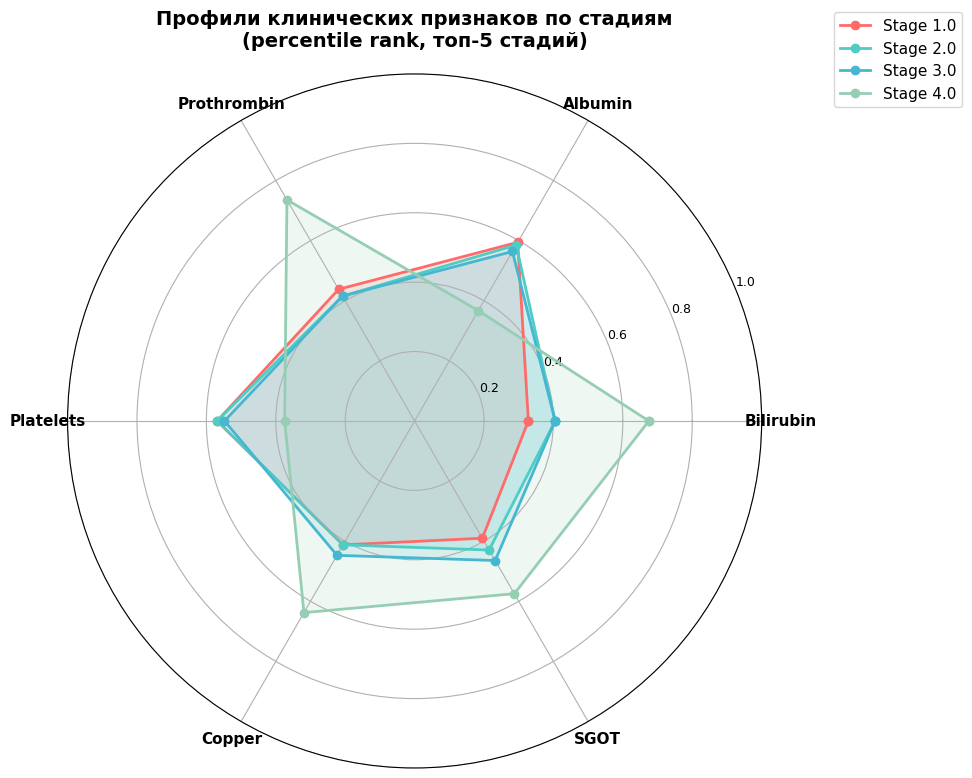

In [ ]:
# 1. Признаки для сравнения
features_for_comparison = ['Bilirubin', 'Albumin', 'Prothrombin',
                           'Platelets', 'Copper', 'SGOT']

# 2. Группы (аналог selected_genres) — топ-5 стадий, например
selected_groups = top_stages_by_days.index.tolist()[:5]   # из предыдущего шага

# 3. Нормализация: percentile rank по всей выборке → [0,1]
df_radar = df.copy()
for c in features_for_comparison:
    df_radar[c] = df_radar[c].rank(pct=True)

# 4. Медианы по группам (в нормализованной шкале)
group_stats = (df_radar[df_radar['Stage'].isin(selected_groups)]
               .groupby('Stage', observed=True)[features_for_comparison]
               .median())

# --- RADAR CHART ---
categories = features_for_comparison
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for idx, group in enumerate(selected_groups):
    values = group_stats.loc[group].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2,
            label=f'Stage {group}', color=colors[idx])
    ax.fill(angles, values, alpha=0.15, color=colors[idx])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)
ax.set_title('Профили клинических признаков по стадиям\n'
             '(percentile rank, топ-5 стадий)',
             fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

D (умершие) vs C (выжившие) Что смотреть: D должен «выпирать» в Bilirubin, Copper, Prothrombin и «проваливаться» в Albumin, Platelets. Если многоугольники почти совпадают — признаки слабо различают исход, и это важный вывод для модели.

/tmp/ipykernel_8237/3874963431.py:45: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_8237/3874963431.py:45: UserWarning: Glyph 128154 (\N{GREEN HEART}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128154 (\N{GREEN HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


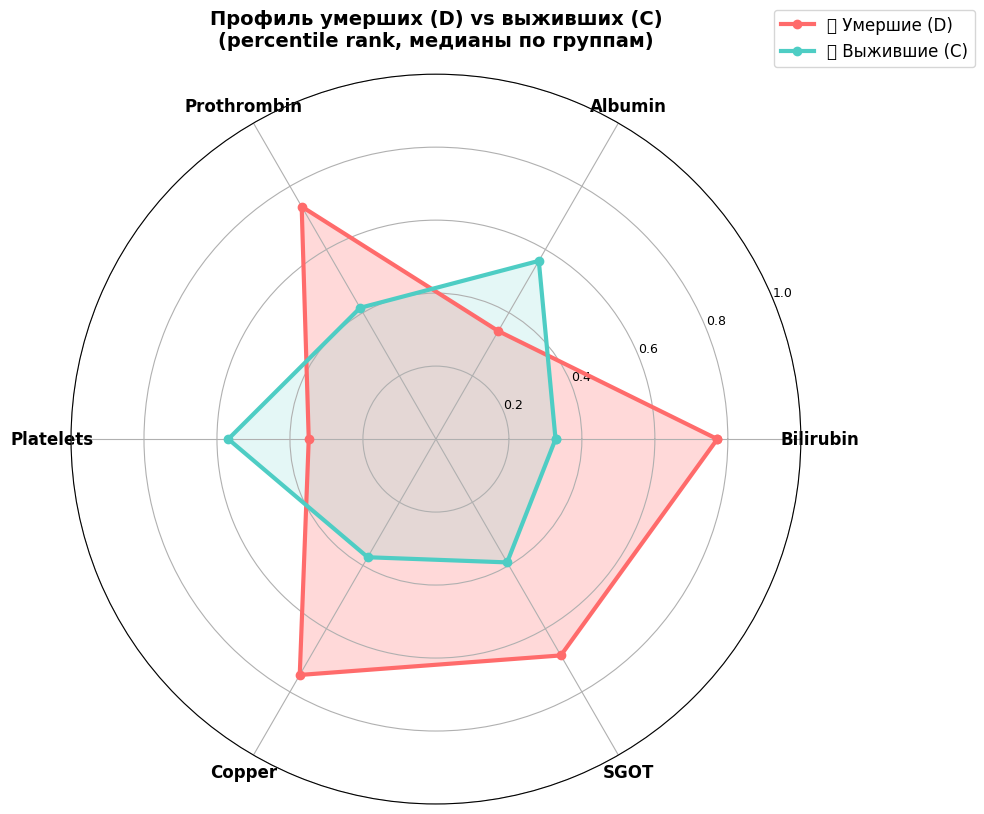

In [ ]:
# 1. Признаки для radar (аналог radar_features) — нормализуем в [0,1]
radar_features = ['Bilirubin', 'Albumin', 'Prothrombin',
                  'Platelets', 'Copper', 'SGOT']

df_radar = df.copy()
# percentile rank → [0,1], аналог того, что audio features уже в [0,1]
for c in radar_features:
    df_radar[c] = df_radar[c].rank(pct=True)

# 2. Бинарная цель: D vs C (аналог is_hit 0/1)
#    CL — очень мало наблюдений, исключаем
df_bin = df_radar[df_radar['Status'].isin(['C', 'D'])]
status_stats = df_bin.groupby('Status', observed=True)[radar_features].median()

# 3. Подготовка radar
categories = radar_features
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)] + [0]   # замкнули

# Значения для D (умершие) и C (выжившие)
values_D = status_stats.loc['D'].values.tolist()
values_D += [values_D[0]]
values_C = status_stats.loc['C'].values.tolist()
values_C += [values_C[0]]

# 4. Фигура
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

ax.plot(angles, values_D, 'o-', linewidth=3, label='💀 Умершие (D)', color='#FF6B6B')
ax.fill(angles, values_D, alpha=0.25, color='#FF6B6B')

ax.plot(angles, values_C, 'o-', linewidth=3, label='💚 Выжившие (C)', color='#4ECDC4')
ax.fill(angles, values_C, alpha=0.15, color='#4ECDC4')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=12)
ax.set_title('Профиль умерших (D) vs выживших (C)\n'
             '(percentile rank, медианы по группам)',
             fontsize=14, fontweight='bold', pad=20)
plt.tight_layout(); plt.show()

тяжёлый пациент vs лёгкий Что смотреть: если «профили» сильно различаются — Stage хорошо согласуется с анализами (что подтверждает клиническую валидность данных). Если почти совпадают — Stage присвоен формально и не отражает тяжесть.

/tmp/ipykernel_8237/4220679004.py:35: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


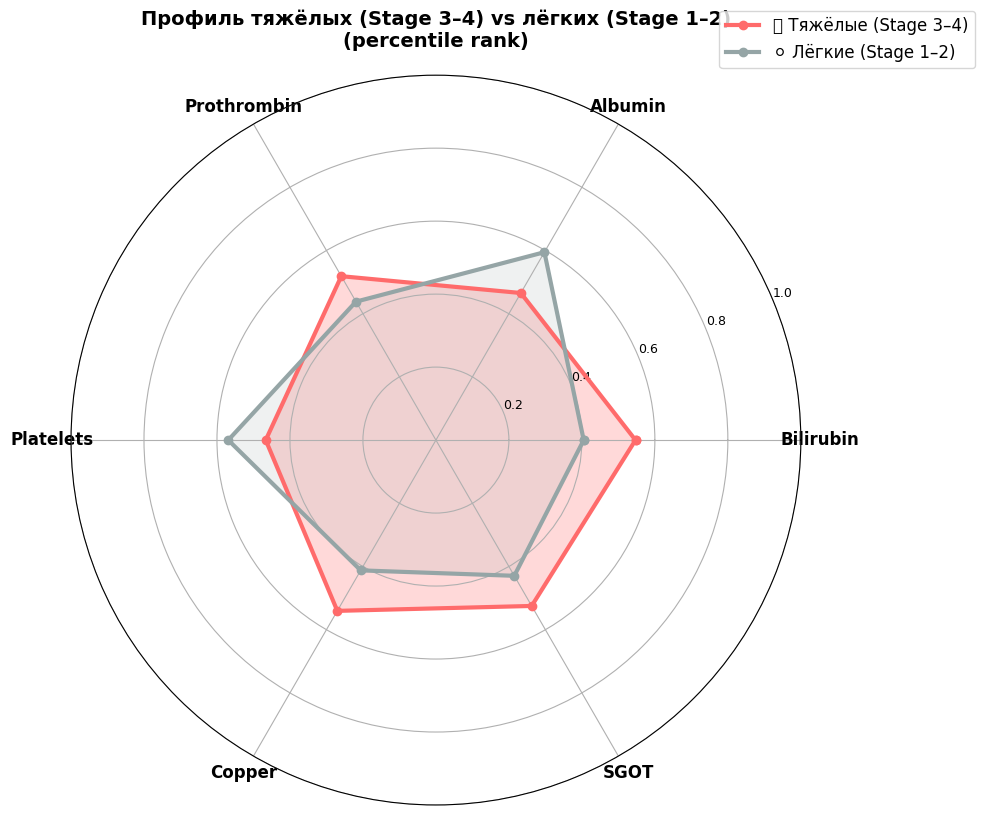

In [ ]:
# is_hit = 1 → тяжёлый (Stage 3-4); is_hit = 0 → лёгкий (Stage 1-2)
df_radar['is_severe'] = (df_radar['Stage'] >= 3).astype(int)

severe_stats = (df_radar[df_radar['Bilirubin'] > 0]  # аналог popularity > 0
                .groupby('is_severe')[radar_features]
                .median())

categories = radar_features
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)] + [0]

values_severe = severe_stats.loc[1].values.tolist(); values_severe += [values_severe[0]]
values_light  = severe_stats.loc[0].values.tolist(); values_light  += [values_light[0]]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

ax.plot(angles, values_severe, 'o-', linewidth=3,
        label='🔴 Тяжёлые (Stage 3–4)', color='#FF6B6B')
ax.fill(angles, values_severe, alpha=0.25, color='#FF6B6B')

ax.plot(angles, values_light, 'o-', linewidth=3,
        label='⚪ Лёгкие (Stage 1–2)', color='#95A5A6')
ax.fill(angles, values_light, alpha=0.15, color='#95A5A6')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=12)
ax.set_title('Профиль тяжёлых (Stage 3–4) vs лёгких (Stage 1–2)\n'
             '(percentile rank)',
             fontsize=14, fontweight='bold', pad=20)
plt.tight_layout(); plt.show()

/tmp/ipykernel_8237/4020093544.py:32: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_8237/4020093544.py:32: UserWarning: Glyph 128154 (\N{GREEN HEART}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128154 (\N{GREEN HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


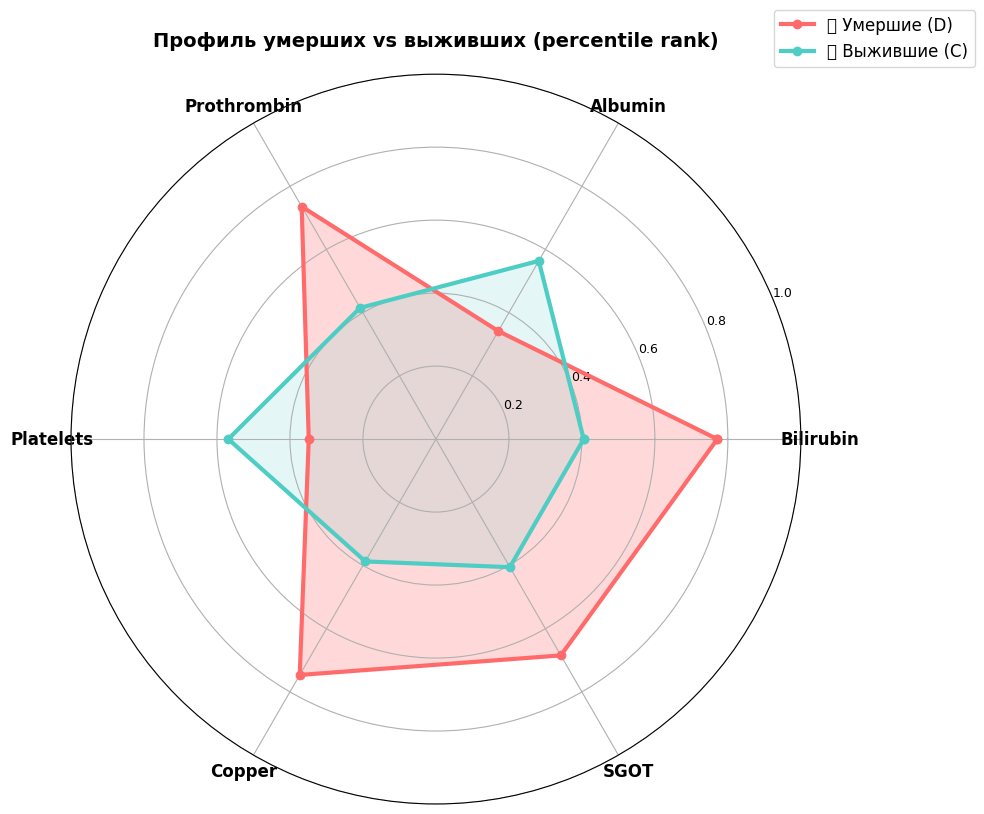

/tmp/ipykernel_8237/4020093544.py:32: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


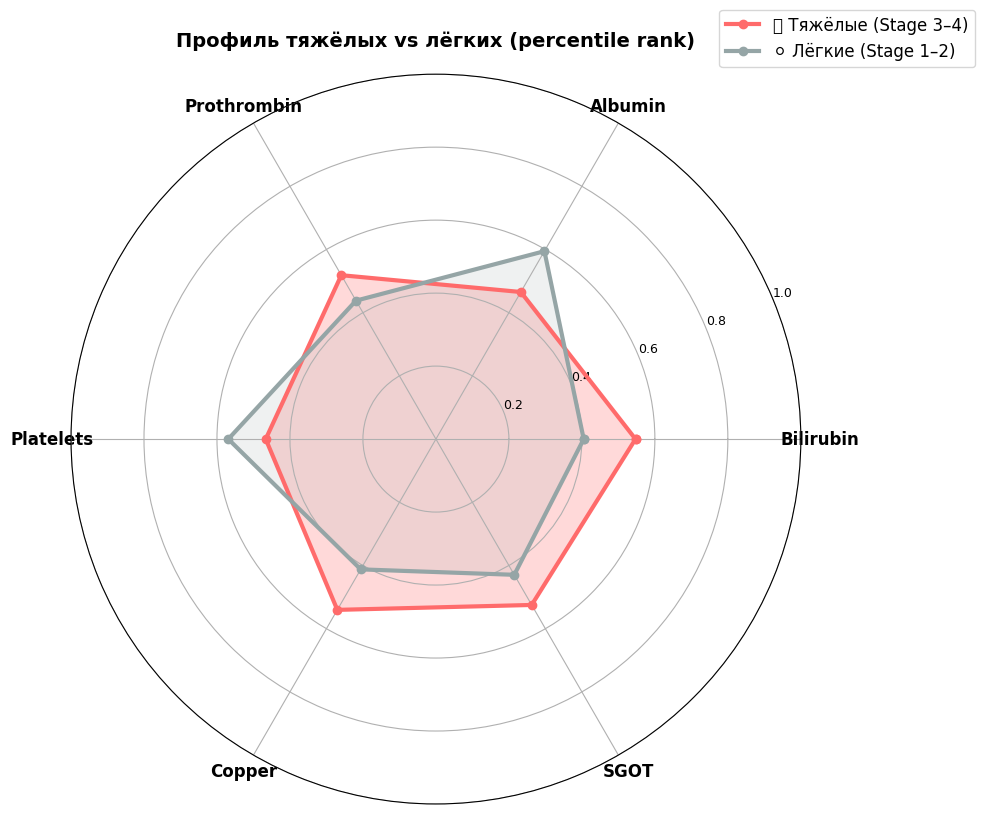

In [ ]:
def radar_binary_compare(df, bin_col, features, label_1, label_0,
                         color_1='#FF6B6B', color_0='#95A5A6',
                         title=None):
    # percentile rank — аналог «все audio features в 0–1»
    data = df.copy()
    for c in features:
        data[c] = data[c].rank(pct=True)

    stats = data.groupby(bin_col, observed=True)[features].median()
    categories = features
    N = len(categories)
    angles = [n / float(N) * 2 * pi for n in range(N)] + [0]

    v1 = stats.loc[1].values.tolist(); v1 += [v1[0]]
    v0 = stats.loc[0].values.tolist(); v0 += [v0[0]]

    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
    ax.plot(angles, v1, 'o-', linewidth=3, label=label_1, color=color_1)
    ax.fill(angles, v1, alpha=0.25, color=color_1)
    ax.plot(angles, v0, 'o-', linewidth=3, label=label_0, color=color_0)
    ax.fill(angles, v0, alpha=0.15, color=color_0)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)

    ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), fontsize=12)
    ax.set_title(title or f'Radar: {label_1} vs {label_0}',
                 fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout(); plt.show()

# Пример: D vs C
df['is_dead'] = (df['Status'] == 'D').astype(int)
radar_binary_compare(
    df, 'is_dead', radar_features,
    label_1='💀 Умершие (D)', label_0='💚 Выжившие (C)',
    color_1='#FF6B6B', color_0='#4ECDC4',
    title='Профиль умерших vs выживших (percentile rank)'
)

# Пример: тяжёлые vs лёгкие
df['is_severe'] = (df['Stage'] >= 3).astype(int)
radar_binary_compare(
    df, 'is_severe', radar_features,
    label_1='🔴 Тяжёлые (Stage 3–4)', label_0='⚪ Лёгкие (Stage 1–2)',
    color_1='#FF6B6B', color_0='#95A5A6',
    title='Профиль тяжёлых vs лёгких (percentile rank)'
)